# The data: a table and a map

<div class="roadmap"><div class="rm-sofar"><span>So far</span>Part 1 of the lecture: there is more data than anyone can read, and machine learning is a way to learn rules from it.</div><div class="rm-question"><b>What does the data look like?</b><span>One row per hexagon: 16 counts of points of interest (the features) and one land-use label. And one place per hexagon on the map.</span></div><div class="rm-steps"><div class="rm-step"><b>The table</b><span>features and label</span></div><div class="rm-step"><b>The map</b><span>where each row lies</span></div><div class="rm-step"><b>The label</b><span>a rule, not a measurement</span></div><div class="rm-step"><b>Neighbours</b><span>adjacent hexagons are alike</span></div></div></div>

The Helsinki region (Helsinki, Espoo, Vantaa and Kauniainen) is divided into 1,459 hexagons, each about 0.57 km². The hexagons are cells of H3, a grid of hexagons that covers the whole globe (week 7). A hexagon is one row of a table and one place on a map. Every page of this site uses this one dataset.

For every hexagon we know two things, both taken from OpenStreetMap:

- **Features:** how many points of interest (POIs) of 16 kinds lie inside it: food places, shops, schools, parking, benches, playgrounds, offices and so on. These 16 counts are the hexagon's **POI profile**.
- **Land-use label:** one of three classes. `green` (forest, parks, fields), `residential`, and `work` (commercial, retail and industrial areas).

The features come from OpenStreetMap's point data and the label from its land-use polygons, so the label is not simply a copy of a feature. The script `build_dataset.py` in the repository shows how the table was made.

```{note}
The code that made a table or a figure is folded above it: click *Show code cell source* to open it. The pages after this one continue the same notebook, so they use the variables defined here.
```

## The table

In [1]:
import os
import warnings

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeClassifier

import helpers as h
from helpers import CLASSES, COLORS, FEATURES

RES = 8      # H3 resolution of the hexagons: 8 (about 0.57 km² each in this region) or 9 (about 0.08 km² each)
SEED = 0     # change it and re-run: how much of a result is luck?
SAVE = os.environ.get("GEOAI_SAVE_FIGS") == "1"   # only used by the teacher, to export the pictures and sliders of the website

In [2]:
hexes = h.load_hexagons(RES)
print(f"{len(hexes):,} hexagons   {int(hexes[FEATURES].sum().sum()):,} points of interest")
print(hexes["landuse"].value_counts().to_string())

# Five hexagons that we follow through this part, and three of the 16 features:
# car = parking and fuel, play = playgrounds and similar, office = offices.
FIVE_PLACES = {"Otaniemi": (24.827, 60.186), "Tikkurila": (25.044, 60.292), "Kontula": (25.080, 60.235),
               "Seurasaari": (24.885, 60.183), "Nuuksio": (24.550, 60.300)}
FIVE = [h.hexagon_at(hexes, lon, lat) for lon, lat in FIVE_PLACES.values()]
SHOW = ["car", "play", "office"]
built_up_pct = ((hexes["share_residential"] + hexes["share_work"]) * 100).to_numpy()   # share of the hexagon that is built-up land
five_rows = hexes.loc[FIVE, ["municipality"] + SHOW + ["poi_total", "landuse"]].copy()
five_rows.insert(0, "place", list(FIVE_PLACES))
five_rows.insert(len(five_rows.columns) - 1, "built_up_pct", built_up_pct[FIVE].round(0))
five_rows.index = range(1, 6)
five_rows

1,459 hexagons   73,404 points of interest
landuse
green          747
residential    569
work           143


,place,municipality,car,play,office,poi_total,built_up_pct,landuse
1,Otaniemi,Espoo,92,2,15,305,28.0,work
2,Tikkurila,Vantaa,64,13,16,338,42.0,residential
3,Kontula,Helsinki,26,7,0,98,59.0,residential
4,Seurasaari,Helsinki,0,7,0,124,0.0,green
5,Nuuksio,Espoo,1,7,0,13,2.0,green


This table is the whole dataset as a model sees it. The count columns are what we know about a hexagon, the **features**, written `X`. The last two columns are things we may want to predict, written `y`.

There are two kinds of question, and the last two columns show one of each.

- **Classification:** the answer is a category. *Which land use does the hexagon have: green, residential or work?* The answer is called a **label**, and a model is scored by its **accuracy**, the share of hexagons it labels correctly. Most pages of this site ask this question.
- **Regression:** the answer is a number. *How much of the hexagon is built-up land?* A model is scored by how far its numbers are from the true ones, for example by **R²**, which the page on supervised learning explains.

The two columns are related: the land-use label is the built-up share turned into a category (the rule is explained below). Interpolation in week 8, with inverse distance weighting or kriging, was regression too: it predicts a number at a place without a measurement.

## The map

A table has no geography in it: the rows could be shuffled and nothing would change. The same five rows have a place on the map.

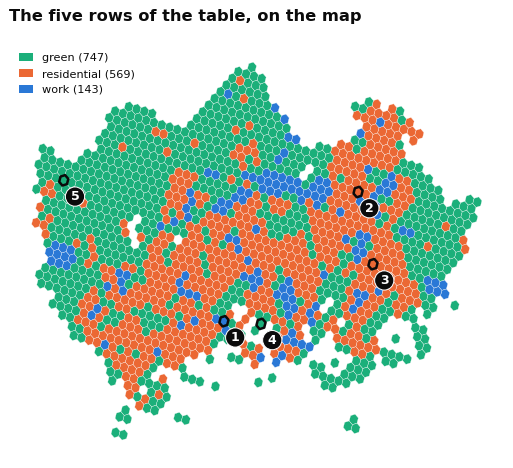

In [3]:
fig, ax = plt.subplots(figsize=(8.6, 6))
h.map_classes(hexes, hexes["landuse"], ax=ax, title="The five rows of the table, on the map", places=False)
h.number_hexagons(ax, hexes, FIVE)
h.save(fig, "0_five_rows_map.png", SAVE)
plt.show()

Point at a hexagon on the map below to read its row of the table. The colour is the land-use label: green for `green`, orange for `residential`, blue for `work`. Zoom in to see the streets, buildings and parks that the counts and the label were taken from.

<iframe src="_static/maps/hexagons.html" class="webmap" title="Interactive map of the hexagons"></iframe>

*Map data and background map © OpenStreetMap contributors.*

In [4]:
if SAVE:    # the interactive map of the website
    h.web_map(hexes, {"municipality": "municipality", "poi_total": "points of interest, all 16 kinds", "car": "parking and fuel",
                      "play": "playgrounds", "office": "offices", "food": "food places", "shop_daily": "daily shops", "education": "schools"})

And here is the whole table on two maps: the label, and how many points of interest a hexagon has.

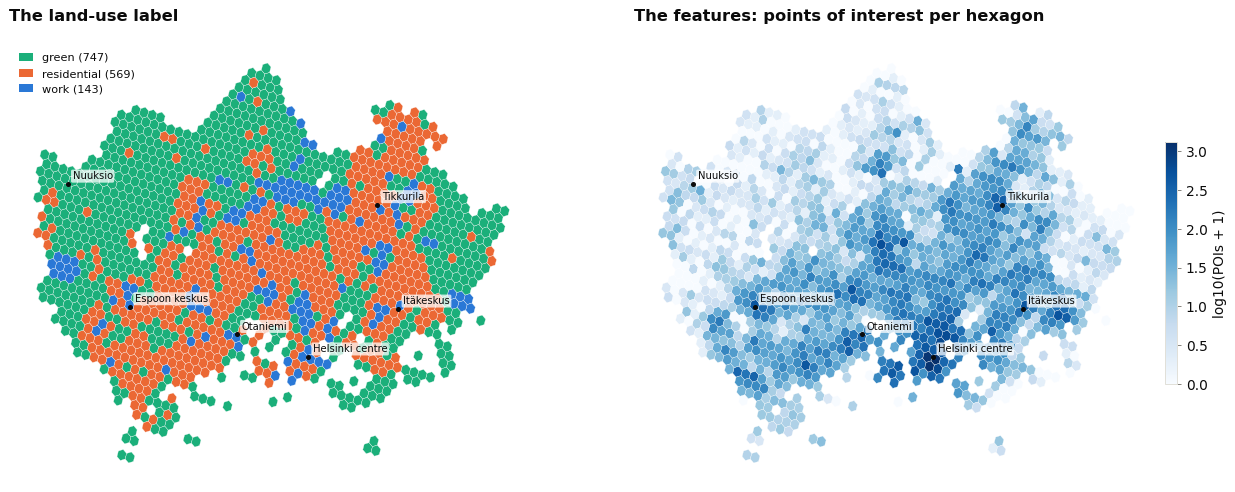

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
h.map_classes(hexes, hexes["landuse"], ax=axes[0], title="The land-use label")
h.map_values(hexes, np.log10(hexes["poi_total"] + 1), ax=axes[1],
             title="The features: points of interest per hexagon", label="log10(POIs + 1)")
plt.tight_layout()
h.save(fig, "0_data_maps.png", SAVE)
plt.show()

The 16 counts of one hexagon, the one that contains the Otaniemi campus, look like this.

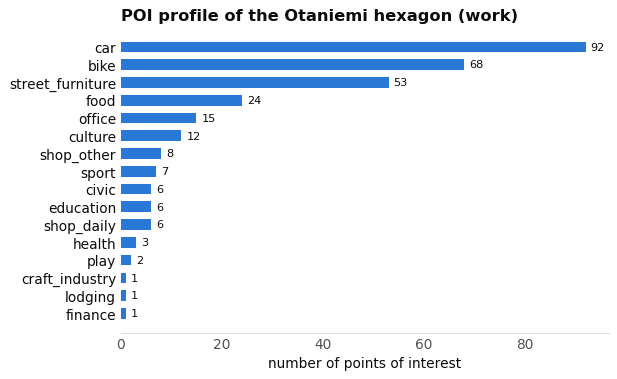

In [6]:
q_otaniemi = h.hexagon_at(hexes, 24.827, 60.186)
profile = hexes.loc[q_otaniemi, FEATURES].astype(float).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.barh(profile.index, profile.values, height=0.6, color="#2a78d6")
for name, v in profile.items():
    ax.text(v + 1, name, f"{int(v)}", va="center", fontsize=9)
ax.set_title(f"POI profile of the Otaniemi hexagon ({hexes.loc[q_otaniemi, 'landuse']})")
ax.set_xlabel("number of points of interest")
ax.tick_params(length=0)
ax.spines["left"].set_visible(False)
h.save(fig, "0_profile_otaniemi.png", SAVE)
plt.show()

## The label is a rule

**The label is a rule, not a measurement.** A hexagon of about 0.57 km² usually holds several land uses, and we give it one name: at least 20% built-up land makes it `residential` or `work`, whichever covers more, and everything else is `green`. How much does that rule decide?

In [7]:
built = hexes["share_residential"] + hexes["share_work"]


def label_with(rule):
    return np.where(built < rule, "green", np.where(hexes["share_work"] >= hexes["share_residential"], "work", "residential"))


assert (label_with(0.20) == hexes["landuse"]).all()
mixed = ((hexes["share_residential"] >= 0.2) & (hexes["share_green"] >= 0.2)).mean()
print(f"{mixed:.0%} of the hexagons are at least 20% residential and at least 20% green.")
for rule in (0.10, 0.30):
    print(f"With a {rule:.0%} rule in place of the 20% rule, {np.mean(label_with(rule) != hexes['landuse']):.0%} of the labels change.")

32% of the hexagons are at least 20% residential and at least 20% green.
With a 10% rule in place of the 20% rule, 13% of the labels change.
With a 30% rule in place of the 20% rule, 12% of the labels change.


> **What did we just see?** Many hexagons are mixed, and a different, equally reasonable rule would name roughly one hexagon in eight differently. The label is also drawn by volunteers. We therefore speak of the *land-use label* and never of the truth, and we should not expect any model to reach 100%.

## Neighbours are alike

The last step prepares the four matrices that the other pages use.

- `X` · the POI profiles, one row per hexagon. We take `log(1 + count)` because a few hexagons in the centre have hundreds of POIs and most have a handful.
- `y` · the land-use label.
- `W` · the **spatial weights matrix** from week 3. Row *i* has the value 1/k for each of the *k* hexagons touching hexagon *i*.
- `X_around` · the **neighbours' profile**: `W @ X`, the average POI profile of the adjacent hexagons. In week 3 this was called the spatial lag.

In [8]:
X = np.log1p(hexes[FEATURES].to_numpy(float))    # own POI profile, 16 numbers per hexagon
y = hexes["landuse"].to_numpy()                  # land-use label
xy = hexes[["x", "y"]].to_numpy()                # centroid coordinates in metres
W = h.neighbour_matrix(hexes)                    # spatial weights (row-standardised)
X_around = W @ X                                 # the neighbours' profile

same_as_neighbours = np.mean([np.mean(y[W[i].indices] == y[i]) for i in range(len(y)) if W[i].nnz])
by_chance = (pd.Series(y).value_counts(normalize=True) ** 2).sum()
print(f"A hexagon shares its land-use label with {same_as_neighbours:.0%} of its neighbours.")
print(f"If the labels were scattered over the map at random, that would be {by_chance:.0%}.")

A hexagon shares its land-use label with 69% of its neighbours.
If the labels were scattered over the map at random, that would be 42%.


> **What did we just see?** Spatial dependence in one number (Tobler's first law, week 3). Adjacent hexagons are far more alike than chance would make them, so a hexagon without a label is not a hexagon about which we know nothing. The pages on semi-supervised learning, on self-supervised learning and on spatially explicit models borrow from that fact, and the page on challenges has to guard against it.

# What is learning?

<div class="roadmap"><div class="rm-sofar"><span>So far</span>The data are a table and a map: one row and one place for every hexagon.</div><div class="rm-question"><b>What does it mean that a machine learns?</b><span>A program learns if its performance at a task improves with experience (Mitchell, 1997).</span></div><div class="rm-steps"><div class="rm-step"><b>Task</b><span>say the land use of a hexagon</span></div><div class="rm-step"><b>Experience</b><span>hexagons whose land use is known</span></div><div class="rm-step"><b>Performance</b><span>the share of new hexagons it gets right</span></div><div class="rm-step"><b>Five ways to learn</b><span>what the learner is given</span></div></div></div>

Part 1 of the lecture gave Tom Mitchell's definition: *a computer program is said to learn from experience E with respect to some class of tasks T and performance measure P, if its performance at tasks in T, as measured by P, improves with experience E.* The definition has three letters, and each has a plain meaning in our table.

| Letter | In the definition | On our hexagons |
|---|---|---|
| T | the task | say the land use of a hexagon from its 16 counts |
| E | the experience | hexagons whose land use the program is given |
| P | the performance measure | accuracy: the share of *other* hexagons whose land use it gets right |

## More experience, better performance

If the definition holds, the performance must rise when the program is given more hexagons with their land use. The cell sets 292 hexagons aside to measure the performance, gives a simple model 10, 20, 50 and more of the remaining hexagons, and repeats each size with 20 different draws.

            mean   min   max
experience                  
10          0.71  0.51  0.78
20          0.75  0.70  0.79
50          0.77  0.72  0.80
100         0.77  0.74  0.80
200         0.79  0.76  0.82
400         0.79  0.78  0.81
1167        0.79  0.79  0.79


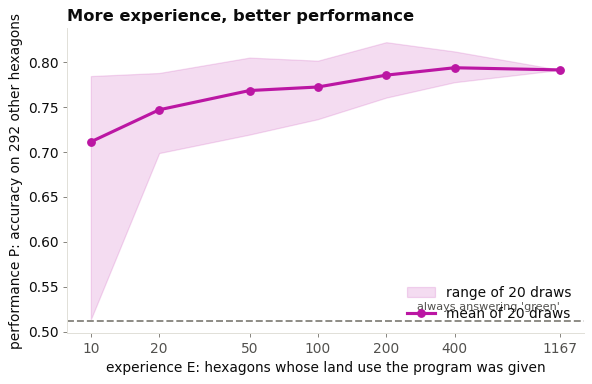

In [9]:
rest, held = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED)      # 292 hexagons are set aside to measure the performance
sizes = [10, 20, 50, 100, 200, 400, len(rest)]
rows = []
for n_known in sizes:
    for draw in range(20):
        known = np.random.default_rng(draw).choice(rest, n_known, replace=False)
        if len(np.unique(y[known])) < 2:        # a draw with one land use only has nothing to tell apart
            continue
        model = LogisticRegression(max_iter=3000).fit(X[known], y[known])
        rows.append({"experience": n_known, "performance": model.score(X[held], y[held])})
learning = pd.DataFrame(rows).groupby("experience")["performance"].agg(["mean", "min", "max"])
print(learning.round(2).to_string())
h.note("learning", {int(k): round(float(v), 2) for k, v in learning["mean"].items()}, SAVE)

fig, ax = plt.subplots(figsize=(7.4, 4.4))
ax.fill_between(learning.index, learning["min"], learning["max"], color=h.ACCENT, alpha=0.15, label="range of 20 draws")
ax.plot(learning.index, learning["mean"], "o-", color=h.ACCENT, lw=2.5, label="mean of 20 draws")
ax.axhline((y == "green").mean(), color=h.MUTED, ls="--", lw=1.5)
ax.text(sizes[-1], (y == "green").mean() + 0.012, "always answering 'green'", ha="right", fontsize=9, color=h.SECONDARY)
ax.set_xscale("log")
ax.set_xticks(sizes, [str(s) for s in sizes])
ax.minorticks_off()
ax.set_xlabel("experience E: hexagons whose land use the program was given")
ax.set_ylabel("performance P: accuracy on 292 other hexagons")
ax.set_title("More experience, better performance")
ax.legend(loc="lower right")
plt.show()

> **What did we just see?** With 10 hexagons the program gets 71% of the other hexagons right on average, and between 51% and 78% depending on which 10 it was given. With 200 hexagons it gets 79%, and the result hardly depends on the draw any more. The performance rose with the experience, so by Mitchell's definition the program learned.
>
> The figure shows two more things. The curve is flat after about 200 hexagons: this simple model cannot use more examples, and the page on supervised learning shows what limits it. And a program that always answers `green` is right for 51% of the hexagons without learning anything, so an accuracy has to be read against that figure.

## Five ways to learn

Part 1 named five ways of learning. They differ in what the learner is given, and each has its page on this site.

| Way of learning | What the learner is given | On our hexagons | Page |
|---|---|---|---|
| Unsupervised | no answers at all | group the hexagons by their counts | [Unsupervised learning](unsupervised) |
| Supervised | an answer for every row | predict land use, or built-up land | [Supervised learning](supervised) |
| Semi-supervised | an answer for a few rows | 30 labels, 1,429 hexagons without | [Semi-supervised learning](semi_supervised) |
| Self-supervised | no answers; a part of the data is hidden and predicted | predict the neighbours of a hexagon from its own counts | [Self-supervised learning](self_supervised) |
| Reinforcement | no table; points for what it does | a courier robot on a grid of streets | [Reinforcement learning](reinforcement) |

# Unsupervised learning: groups without names

<div class="roadmap"><div class="rm-sofar"><span>So far</span>A program learns if its performance at a task improves with experience.</div><div class="rm-question"><b>What can be found in data when nobody says what to look for?</b><span>Clustering: k-means puts the hexagons into K groups with similar counts. No label is used.</span></div><div class="rm-steps"><div class="rm-step"><b>k-means</b><span>centres, nearest centre, move, repeat</span></div><div class="rm-step"><b>Groups on the map</b><span>three groups, without names</span></div><div class="rm-step"><b>How many groups?</b><span>the elbow method</span></div><div class="rm-step"><b>Groups and labels</b><span>who names a group?</span></div></div></div>

On this page the land-use label is put aside. All the method sees is the 16 counts of every hexagon.

## 1. How k-means works

Clustering groups observations so that those within a group are as similar as possible and those of different groups as dissimilar as possible. The best-known method is **k-means**, and it needs one number from us: K, the number of groups. It then repeats two steps.

1. Put every hexagon into the group whose centre is nearest.
2. Move every centre to the average of its group.

It stops when no hexagon changes its group. The slider shows these steps for two of the 16 counts, because two counts can be drawn. At the start the three centres are three hexagons picked at random.

In [10]:
two_counts = X[:, [FEATURES.index("car"), FEATURES.index("play")]]          # parking and fuel, playgrounds: two counts that can be drawn


def kmeans_steps(points, k=3, steps=8, seed=3):
    """k-means written out: returns, for every step, the centres and the group of every point."""
    centres = points[np.random.default_rng(seed).choice(len(points), k, replace=False)]
    history = []
    for _ in range(steps):
        group = np.argmin(((points[:, None, :] - centres[None, :, :]) ** 2).sum(axis=2), axis=1)      # step 1: the nearest centre
        history.append((centres.copy(), group))
        centres = np.array([points[group == g].mean(axis=0) if (group == g).any() else centres[g] for g in range(k)])   # step 2: move the centres
    return history


steps_2d = kmeans_steps(two_counts)
print("hexagons that change their group from one step to the next:",
      [int((steps_2d[i][1] != steps_2d[i - 1][1]).sum()) for i in range(1, len(steps_2d))])

hexagons that change their group from one step to the next: [244, 34, 18, 10, 5, 2, 0]


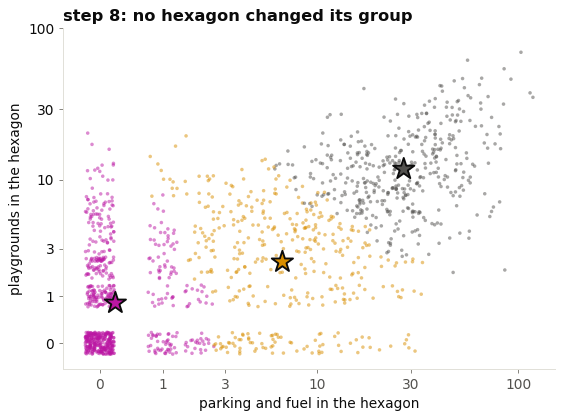

In [11]:
def draw_step(i):
    centres, group = steps_2d[i]
    fig, ax = plt.subplots(figsize=(6.4, 4.8))
    P = h.spread(two_counts, 0.16)
    ax.scatter(P[:, 0], P[:, 1], s=8, color=[h.CLUSTER_COLORS[g] for g in group], alpha=0.5, linewidths=0)
    ax.scatter(centres[:, 0], centres[:, 1], s=320, marker="*", color=[h.CLUSTER_COLORS[g] for g in range(len(centres))], edgecolor=h.INK, linewidths=1.5, zorder=5)
    h.count_ticks(ax, "x", (0, 1, 3, 10, 30, 100)), h.count_ticks(ax, "y", (0, 1, 3, 10, 30, 100))
    ax.set_xlabel("parking and fuel in the hexagon"), ax.set_ylabel("playgrounds in the hexagon")
    changed = int((group != steps_2d[i - 1][1]).sum()) if i else None
    ax.set_title(f"step {i + 1}: every hexagon joins its nearest centre (star)" if i == 0 else
                 f"step {i + 1}: {changed} hexagons changed their group" if changed else f"step {i + 1}: no hexagon changed its group")
    fig.tight_layout()
    return fig


fig = draw_step(len(steps_2d) - 1)
plt.show()
if SAVE:
    h.frames(draw_step, range(len(steps_2d)), "kmeans_steps")

<div class="frames" data-name="kmeans_steps" data-prefix="step" data-first="1"></div>

*k-means on two counts, step by step. The stars are the centres. The colours tell the groups apart and have no other meaning.*

## 2. Three groups on the map

Now all 16 counts are used, and K is set to 3. The map on the left shows the groups that k-means found. The map on the right shows the land-use label, which k-means never saw.

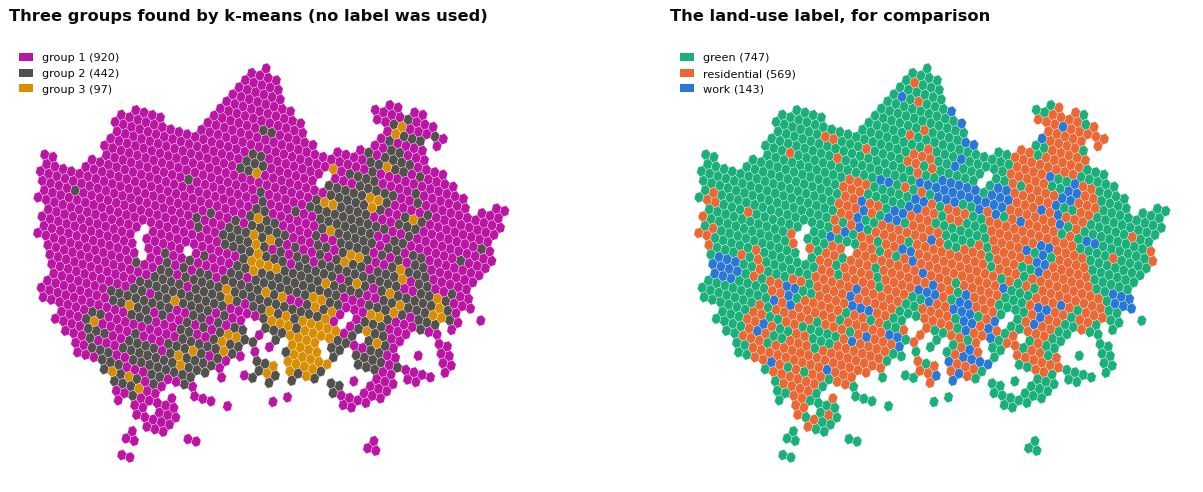

In [12]:
Zk = StandardScaler().fit_transform(X)                 # every count on the same scale, so that no count outweighs the others
KS = list(range(2, 9))
kmeans = {k: KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Zk) for k in KS}
groups = kmeans[3].labels_

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
h.map_clusters(hexes, groups, ax=axes[0], title="Three groups found by k-means (no label was used)")
h.map_classes(hexes, y, ax=axes[1], title="The land-use label, for comparison", places=False)
plt.tight_layout()
plt.show()


def draw_k(k):
    fig, ax = plt.subplots(figsize=(8.6, 6))
    h.map_clusters(hexes, kmeans[k].labels_, ax=ax, title=f"k-means with K = {k}")
    return fig


if SAVE:
    h.frames(draw_k, KS, "kmeans")

The groups form patches on the map although k-means was given no coordinates: hexagons with similar counts tend to lie next to each other (step 4 puts a number on this). With another K the same hexagons fall into other groups; move the slider.

<div class="frames" data-name="kmeans" data-labels="K = 2|K = 3|K = 4|K = 5|K = 6|K = 7|K = 8"></div>

*The groups of k-means for K from 2 to 8.*

## 3. How many groups?

Nothing in the data says what K should be. The **elbow method** of part 1 of the lecture runs k-means for several values of K and plots, for each, how far the hexagons lie from the centre of their group (the within-cluster sum of squares). The value falls with every added group; one looks for the K after which it falls only slowly.

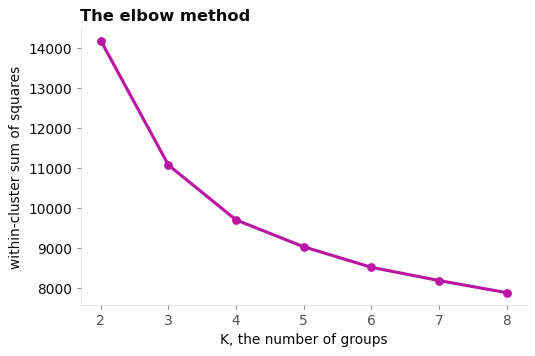

fall of the sum of squares with each added group: {'2 to 3': '22%', '3 to 4': '12%', '4 to 5': '7%', '5 to 6': '6%', '6 to 7': '4%', '7 to 8': '4%'}


In [13]:
wcss = pd.Series({k: kmeans[k].inertia_ for k in KS})
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.plot(wcss.index, wcss.values, "o-", color=h.ACCENT, lw=2.5)
ax.set_xlabel("K, the number of groups")
ax.set_ylabel("within-cluster sum of squares")
ax.set_title("The elbow method")
plt.show()
print("fall of the sum of squares with each added group:", {f"{k - 1} to {k}": f"{1 - wcss[k] / wcss[k - 1]:.0%}" for k in KS[1:]})
h.note("elbow", {int(k): round(float(1 - wcss[k] / wcss[k - 1]), 3) for k in KS[1:]}, SAVE)

> **What did we just see?** The third group reduces the sum of squares by 22%, the fourth by 12%, the fifth by 7%, and every later group by 6% or less. The curve bends between K = 3 and K = 4 and has no sharp elbow, which is common with real data. The elbow method therefore gives a range, and the choice within the range depends on what the groups are for. We keep K = 3, because the land-use label has three classes and the next step compares the groups with it.

## 4. Groups and labels: who names a group?

k-means returns group 1, group 2 and group 3. It does not say what they are. The table counts, for each group, how many of its hexagons carry each land-use label.

In [14]:
table = pd.crosstab(pd.Series(groups + 1, name="group"), pd.Series(y, name="land use"))
table["hexagons"] = table.sum(axis=1)
table["median POIs"] = pd.Series(hexes["poi_total"].to_numpy()).groupby(groups + 1).median().astype(int)      # points of interest in a typical hexagon of the group
named = table[CLASSES].idxmax(axis=1)                       # the most frequent land use of each group
agree = float((named.reindex(groups + 1).to_numpy() == y).mean())
print(table.to_string())
print("\nmost frequent land use of each group:", named.to_dict())
print(f"If every group is named after its most frequent land use, {agree:.0%} of the hexagons get their own label (always answering 'green': {(y == 'green').mean():.0%}).")
same_group = np.mean([np.mean(groups[W[i].indices] == groups[i]) for i in range(len(groups)) if W[i].nnz])
group_chance = (pd.Series(groups).value_counts(normalize=True) ** 2).sum()
print(f"A hexagon shares its group with {same_group:.0%} of its neighbours (if the groups were scattered at random: {group_chance:.0%}).")
h.note("clusters", {"named": {int(k): v for k, v in named.items()}, "agree": round(agree, 3), "same_group": round(float(same_group), 2),
                    "chance": round(float(group_chance), 2)}, SAVE)

land use  green  residential  work  hexagons  median POIs
group                                                    
1           670          184    66       920            4
2            73          314    55       442           69
3             4           71    22        97          242

most frequent land use of each group: {1: 'green', 2: 'residential', 3: 'residential'}
If every group is named after its most frequent land use, 72% of the hexagons get their own label (always answering 'green': 51%).


A hexagon shares its group with 73% of its neighbours (if the groups were scattered at random: 49%).


> **What did we just see?** Group 1 holds 920 hexagons, of which 670 are green. Group 2 is mostly residential. Group 3, with 97 hexagons, is mostly residential too, and no group is mostly work. k-means therefore did not find the three land uses. The last column shows what it found: a typical hexagon has 4 points of interest in group 1, 69 in group 2 and 242 in group 3. The groups are three levels of activity.
>
> Two points follow. First, the groups come without names. To name them we needed the land-use label, which is an answer from outside the counts, and even then only 72% of the hexagons receive their own label (51% if every hexagon is called green). Second, a clustering answers the question that the features pose, here *how much is there in a hexagon?*, and that need not be the question we have in mind. The page on supervised learning gives the method the answers.
>
> The last printed line supports what the maps showed: a hexagon shares its group with 73% of its neighbours, against 49% for groups scattered at random, although k-means never saw a coordinate.

# Supervised learning: how a model learns

<div class="roadmap"><div class="rm-sofar"><span>So far</span>Clustering found groups in the counts, and could not name them.</div><div class="rm-question"><b>What does it mean to learn from examples?</b><span>A rule with adjustable numbers is fitted to rows with known answers, and scored on rows it has never seen.</span></div><div class="rm-steps"><div class="rm-step"><b>Two tasks</b><span>a category or a number</span></div><div class="rm-step"><b>A rule with parameters</b><span>a line, a boundary</span></div><div class="rm-step"><b>Training</b><span>the computer sets the parameters</span></div><div class="rm-step"><b>Unseen rows</b><span>the honest score</span></div><div class="rm-step"><b>Flexibility</b><span>how freely the rule may bend</span></div></div></div>

Part 1 of the lecture said what supervised learning is: a model learns a mapping from inputs to outputs from examples with known answers, in order to predict the answers for new, unseen data. This page takes that sentence apart in ten steps.

## 1. Two tasks: a category or a number

First two pictures with made-up points. On the left every point is an object seen from the air, and for each we know whether it is a tree or a building. For a new object we want the answer *tree* or *building*, which is a category: this task is called **classification**. On the right every point is a flat whose rent we know. For a new flat we want a number of euros: this task is called **regression**.

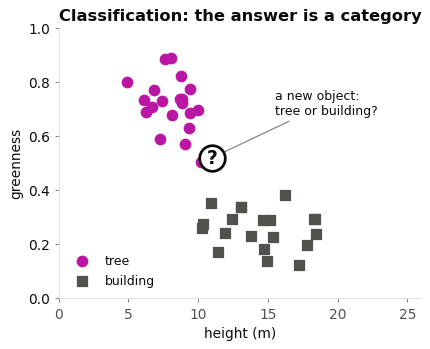

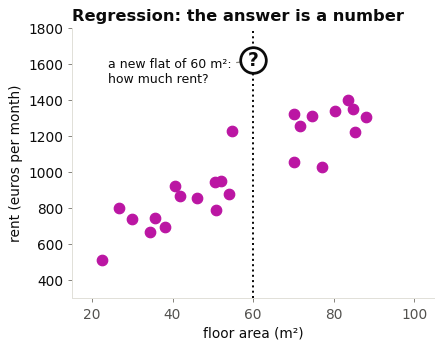

In [15]:
toy = np.random.default_rng(1)          # made-up data, for these two pictures only
trees = np.c_[toy.normal(8, 2.4, 20), toy.normal(0.72, 0.08, 20)]            # height in metres, greenness between 0 and 1
buildings = np.c_[toy.normal(15, 3.8, 20), toy.normal(0.27, 0.09, 20)]
area = toy.uniform(22, 98, 24)                                               # floor area of a flat, in square metres
rent = 300 + 12.5 * area + toy.normal(0, 95, 24)                             # its monthly rent, in euros

fig_c, ax = plt.subplots(figsize=(5.2, 3.9))
ax.scatter(*trees.T, s=70, marker="o", color=h.ACCENT, label="tree")
ax.scatter(*buildings.T, s=70, marker="s", color=h.SECONDARY, label="building")
ax.scatter([11], [0.52], s=420, marker="o", facecolor="white", edgecolor=h.INK, linewidths=2.2, zorder=5)
ax.annotate("?", (11, 0.52), ha="center", va="center", fontsize=15, fontweight="bold", zorder=6)
ax.annotate("a new object:\ntree or building?", (11, 0.52), xytext=(15.5, 0.72), fontsize=10, ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color=h.MUTED, shrinkB=11))
ax.set_xlabel("height (m)"), ax.set_ylabel("greenness")
ax.set_xlim(0, 26), ax.set_ylim(0, 1)
ax.legend(loc="lower left", fontsize=10)
ax.set_title("Classification: the answer is a category")
h.save(fig_c, "0_toy_classification.png", SAVE, untitled=True)

fig_r, ax = plt.subplots(figsize=(5.2, 3.9))
ax.scatter(area, rent, s=70, color=h.ACCENT)
ax.axvline(60, color=h.INK, lw=1.6, ls=":")
ax.scatter([60], [1620], s=420, marker="o", facecolor="white", edgecolor=h.INK, linewidths=2.2, zorder=5)
ax.annotate("?", (60, 1620), ha="center", va="center", fontsize=15, fontweight="bold", zorder=6)
ax.annotate("a new flat of 60 m²:\nhow much rent?", (60, 1620), xytext=(24, 1560), fontsize=10, ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color=h.MUTED, shrinkB=11))
ax.set_xlabel("floor area (m²)"), ax.set_ylabel("rent (euros per month)")
ax.set_xlim(15, 105), ax.set_ylim(300, 1800)
ax.set_title("Regression: the answer is a number")
h.save(fig_r, "0_toy_regression.png", SAVE, untitled=True)
plt.show()

Both tasks need rows whose answer is known, and this makes them **supervised learning**. When no answers are known, a method such as k-means (the page on unsupervised learning) can still find groups of similar rows. That is clustering, and it differs from classification in one respect: the groups come without names, so someone has to decide afterwards what each group is. Remote sensing calls this procedure *unsupervised classification*: the pixels are clustered first and the clusters are named afterwards.

## 2. The same two tasks on our hexagons

Our table holds one answer of each kind. The land-use label is a category, and the share of built-up land is a number. The numbers 1 to 5 on the maps are the five hexagons of the table on the page [The data](data): Otaniemi, Tikkurila, Kontula, Seurasaari and Nuuksio.

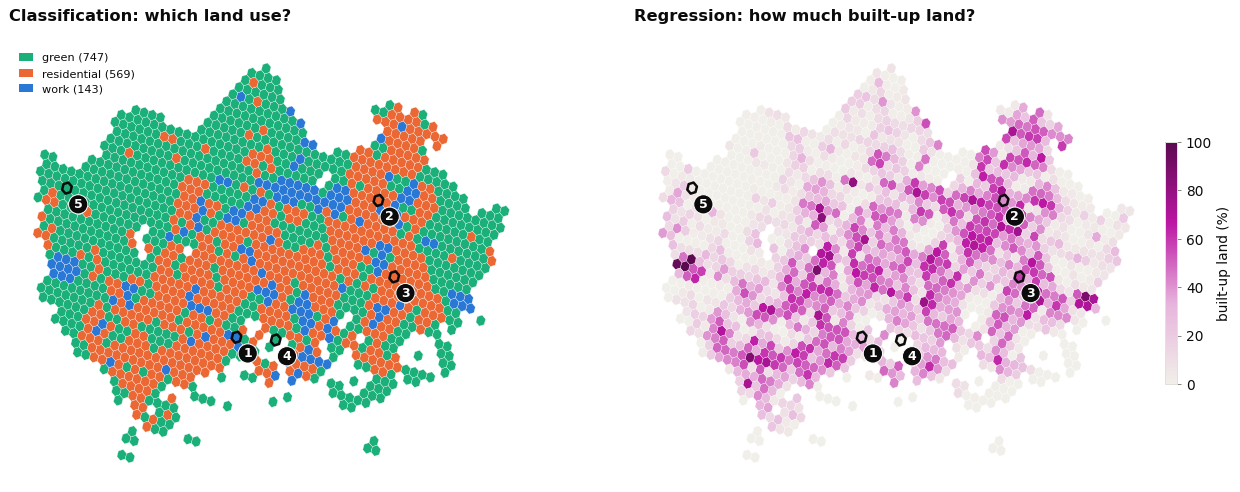

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
h.map_classes(hexes, y, ax=axes[0], title="Classification: which land use?", places=False)
h.map_values(hexes, built_up_pct, ax=axes[1], title="Regression: how much built-up land?", label="built-up land (%)",
             cmap=h.accent_cmap(), places=False)
for ax in axes:
    h.number_hexagons(ax, hexes, FIVE)
plt.tight_layout()
plt.show()

if SAVE:    # small maps for the corners of the slides: the same five rows on every one of them
    small = {"0_inset_landuse.png": dict(labels=y), "0_inset_builtup.png": dict(values=built_up_pct),
             "0_inset_pois.png": dict(values=np.log10(1 + hexes["poi_total"].to_numpy(float)))}
    for name, what in small.items():
        fig = h.inset_map(hexes, rows=FIVE, **what)
        h.save(fig, name)
        plt.close(fig)
    fig, ax = plt.subplots(figsize=(8.6, 6))
    h.map_classes(hexes, y, ax=ax, places=False)
    h.number_hexagons(ax, hexes, FIVE)
    h.save(fig, "0_five_rows_map_plain.png")
    plt.close(fig)

## 3. A number: more points of interest, more built-up land

We take the regression task first. In the plot below every dot is a hexagon: its number of points of interest runs across, and its share of built-up land runs upwards. The horizontal axis is stretched (it is logarithmic), because a few hexagons in the centre hold hundreds of points of interest and most hold a handful. The purpose of the plot is one question: do hexagons with more points of interest have more built-up land?

median share of built-up land (%), by the number of points of interest in the hexagon
none              0.0
1 to 10           6.0
11 to 50         29.0
51 to 200        42.0
more than 200    39.0


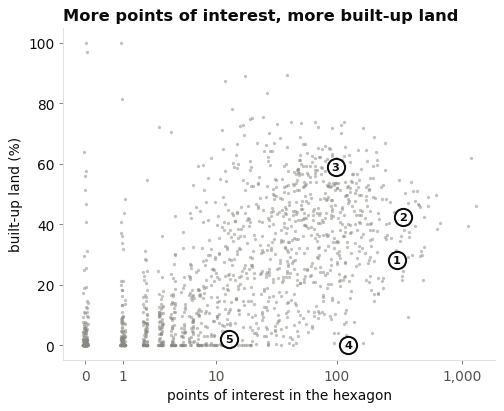

In [17]:
poi_total = hexes["poi_total"].to_numpy(float)
poi_log = np.log10(1 + poi_total).reshape(-1, 1)        # log10(1 + count): the values 0, 1, 2, 3 stand for 0, 9, 99 and 999 points of interest
xs = np.linspace(0, poi_log.max(), 400).reshape(-1, 1)


def poi_scatter(ax):
    """Every hexagon as a dot: points of interest across, built-up land upwards. The five rows of the table are numbered."""
    ax.scatter(h.spread(poi_log.ravel(), 0.02), built_up_pct, s=7, color=h.MUTED, alpha=0.5, linewidths=0)
    for n, i in enumerate(FIVE, 1):
        ax.scatter(poi_log[i, 0], built_up_pct[i], s=190, facecolor="white", edgecolor=h.INK, linewidths=1.6, zorder=6)
        ax.annotate(str(n), (poi_log[i, 0], built_up_pct[i]), ha="center", va="center", fontsize=9, fontweight="bold", zorder=7)
    h.count_ticks(ax, "x", [0, 1, 10, 100, 1000], lambda c: np.log10(1 + c))
    ax.set_ylim(-5, 105)
    ax.set_xlabel("points of interest in the hexagon")
    ax.set_ylabel("built-up land (%)")


bands = pd.cut(pd.Series(poi_total), [-1, 0, 10, 50, 200, 5000], labels=["none", "1 to 10", "11 to 50", "51 to 200", "more than 200"])
by_band = pd.Series(built_up_pct).groupby(bands, observed=True).median().round(0)
print("median share of built-up land (%), by the number of points of interest in the hexagon")
print(by_band.to_string())
h.note("bands", {k: int(v) for k, v in by_band.items()}, SAVE)

fig, ax = plt.subplots(figsize=(6.2, 4.8))
poi_scatter(ax)
ax.set_title("More points of interest, more built-up land")
h.save(fig, "0_relationship.png", SAVE, untitled=True)
plt.show()

The data suggest a relationship: without points of interest the typical hexagon has no built-up land, and with 51 to 200 of them it has about four tenths. Such a statement is still loose. To predict with it we have to state it as a rule that returns one number for any hexagon.

## 4. A model: a line with two parameters

The simplest rule of this kind is a straight line. Call the feature x and the answer y; the line is then *y = a + b × x*. It has two numbers in it. The number **a** is where the line starts, and the number **b** is how steep it is. These numbers are the **parameters** of the model. The picture shows three choices of a and b for a few made-up points. Every choice gives another line, and every line lies at another distance from the points. That distance is the **error** of the line: the short vertical strokes show it point by point, and the typical error is their root mean square.

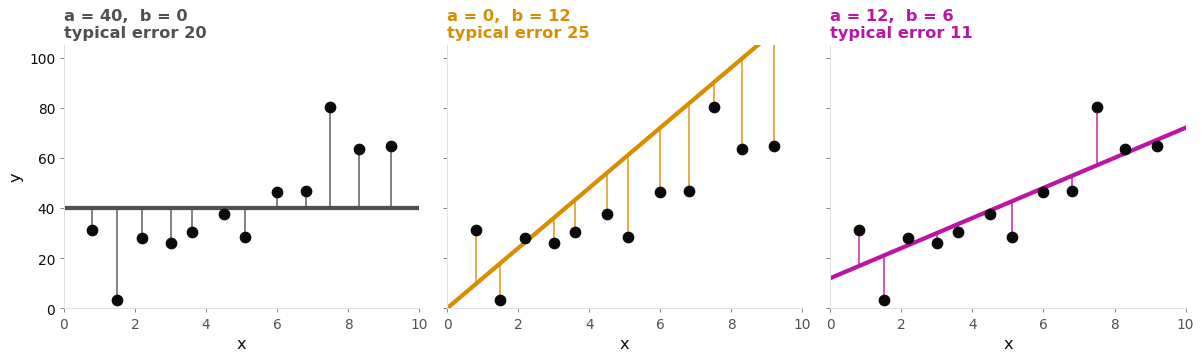

In [18]:
toy_x = np.array([0.8, 1.5, 2.2, 3.0, 3.6, 4.5, 5.1, 6.0, 6.8, 7.5, 8.3, 9.2])          # made-up points, for this picture only
toy_y = 12 + 6 * toy_x + np.random.default_rng(3).normal(0, 7, len(toy_x))


def toy_error(a, b):
    """The typical error of the line y = a + b x on the made-up points: the root of the mean squared distance."""
    return float(np.sqrt(((a + b * toy_x - toy_y) ** 2).mean()))


choices = [(40, 0, h.SECONDARY), (0, 12, "#d98e00"), (12, 6, h.ACCENT)]          # a, b and the colour of the line
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2), sharey=True)
for ax, (a, b, colour) in zip(axes, choices):
    ax.vlines(toy_x, toy_y, a + b * toy_x, color=colour, lw=1.6, alpha=0.7)          # the error, point by point
    ax.plot([0, 10], [a, a + 10 * b], color=colour, lw=3.4)
    ax.scatter(toy_x, toy_y, s=70, color=h.INK, zorder=3)
    ax.set_title(f"a = {a},  b = {b}\ntypical error {toy_error(a, b):.0f}", color=colour, fontsize=14)
    ax.set_xlim(0, 10), ax.set_ylim(0, 105)
    ax.set_xlabel("x", fontsize=13)
axes[0].set_ylabel("y", fontsize=13)
plt.tight_layout()
h.save(fig, "0_line_parameters.png", SAVE)
plt.show()
h.note("toy_points", {"x": [round(float(v), 2) for v in toy_x], "y": [round(float(v), 1) for v in toy_y]}, SAVE)
h.note("toy_line", [{"a": a, "b": b, "error": round(toy_error(a, b))} for a, b, _ in choices], SAVE)

**Try it.** Move a and b. The short strokes are the errors, and the number is the typical error of your line. Can you get below 11?

<div class="linelab"></div>

On our hexagons, x is the number of points of interest and y is the share of built-up land. Since the counts run from 0 to more than a thousand, x is read on the stretched axis of step 3 (it is log10 of 1 + the count, so that one step of x stands for about ten times as many points of interest). The cell fits the line with the smallest error and shows, for the five rows of the table, what the line says and by how much it is off.

In [19]:
line = LinearRegression().fit(poi_log, built_up_pct)
a_fit, b_fit = float(line.intercept_), float(line.coef_[0])


def typical_error(a, b):
    """How far a line lies from the hexagons: the root of the mean squared error, in points of built-up share."""
    return float(np.sqrt(((a + b * poi_log.ravel() - built_up_pct) ** 2).mean()))


line_rows = pd.DataFrame({"place": list(FIVE_PLACES), "points of interest": poi_total[FIVE].astype(int),
                          "built-up land (%)": built_up_pct[FIVE].round(0).astype(int),
                          "the line says (%)": line.predict(poi_log[FIVE]).round(0).astype(int)}, index=range(1, 6))
line_rows["error"] = line_rows["the line says (%)"] - line_rows["built-up land (%)"]
new_row = int(round(a_fit + b_fit * np.log10(1 + 50)))
print(f"y = {a_fit:.1f} + {b_fit:.1f} x, with x = log10(1 + number of POIs) and y = built-up land (%)       R2 = {line.score(poi_log, built_up_pct):.2f}")
print(f"typical error: {typical_error(0, 0):.0f} points with a = 0, b = 0;  {typical_error(built_up_pct.mean(), 0):.0f} with a flat line at the average;  "
      f"{typical_error(a_fit, b_fit):.0f} with the fitted line")
print(f"a new hexagon with 50 points of interest: the line answers {new_row}% built-up land")
h.note("line", {"a": round(a_fit, 1), "b": round(b_fit, 1), "r2": round(float(line.score(poi_log, built_up_pct)), 2),
                "error_zero": round(typical_error(0, 0)), "error_flat": round(typical_error(built_up_pct.mean(), 0)),
                "error_fit": round(typical_error(a_fit, b_fit)), "mean": round(float(built_up_pct.mean())), "new_row_50": new_row,
                "rows": line_rows.reset_index(drop=True).to_dict("records")}, SAVE)
line_rows

y = 2.7 + 17.8 x, with x = log10(1 + number of POIs) and y = built-up land (%)       R2 = 0.38
typical error: 32 points with a = 0, b = 0;  21 with a flat line at the average;  17 with the fitted line
a new hexagon with 50 points of interest: the line answers 33% built-up land


,place,points of interest,built-up land (%),the line says (%),error
1,Otaniemi,305,28,47,19
2,Tikkurila,338,42,48,6
3,Kontula,98,59,38,-21
4,Seurasaari,124,0,40,40
5,Nuuksio,13,2,23,21


For Tikkurila the fitted line is 6 points too high, for Kontula 21 points too low, and for Seurasaari, an island with an open-air museum and no built-up land, 40 points too high. Over all hexagons the typical error of this line is 17 points, and **R²** is 0.38: the line accounts for 38% of the differences between hexagons (0 for a flat line at the average, 1 for a rule that hits every dot).

## 5. Training: the computer finds the parameters

We chose the form of the rule, a line. We do not choose a and b: the computer finds them from the rows whose answer is known. It starts somewhere, measures the error of the line, changes both numbers a little in the direction that reduces the error, and repeats. This is called **training** or **fitting**. The cell below does exactly that (the method is called gradient descent) and prints a few of the steps.

In [20]:
def fitting_path(x, t, shown=(0, 1, 2, 4, 8, 16, 32, 300), rate=0.2):
    """Fit t = a + b * x step by step, and return a and b after the steps listed in `shown`."""
    z = (x - x.mean()) / x.std()                     # the same x on a scale that makes the steps even
    a, b, path = 0.0, 0.0, {}
    for step in range(max(shown) + 1):
        if step in shown:
            path[step] = (a - b * x.mean() / x.std(), b / x.std())        # back on the original scale
        off = a + b * z - t
        a, b = a - rate * off.mean(), b - rate * (off * z).mean()
    return path


path = fitting_path(poi_log.ravel(), built_up_pct)
for step, (a, b) in path.items():
    print(f"step {step:3d}: a = {a:5.1f}, b = {b:4.1f}, typical error {typical_error(a, b):4.1f} points")
h.note("training", {"error_start": round(typical_error(*path[0]), 1), "error_end": round(typical_error(*path[300]), 1), "steps": 300}, SAVE)

step   0: a =   0.0, b =  0.0, typical error 31.9 points
step   1: a =   0.5, b =  3.6, typical error 27.4 points
step   2: a =   1.0, b =  6.4, typical error 24.2 points
step   4: a =   1.6, b = 10.5, typical error 20.2 points
step   8: a =   2.3, b = 14.8, typical error 17.5 points
step  16: a =   2.6, b = 17.3, typical error 17.0 points
step  32: a =   2.7, b = 17.8, typical error 16.9 points
step 300: a =   2.7, b = 17.8, typical error 16.9 points


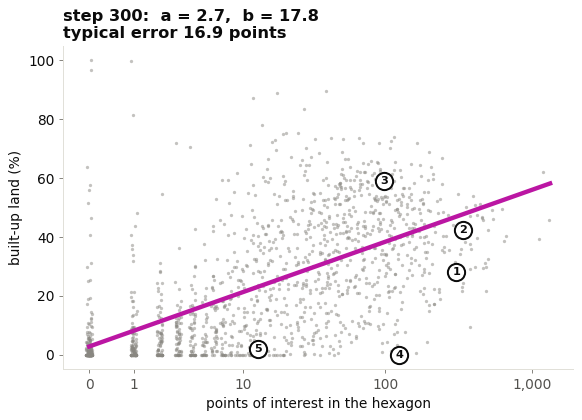

In [21]:
def draw_fit(step):
    a, b = path[step]
    fig, ax = plt.subplots(figsize=(6.6, 4.8))
    poi_scatter(ax)
    ax.plot(xs, a + b * xs.ravel(), color=h.ACCENT, lw=3.5)
    ax.set_title(f"step {step}:  a = {a:.1f},  b = {b:.1f}\ntypical error {typical_error(a, b):.1f} points", fontsize=12)
    fig.tight_layout()
    return fig


fig = draw_fit(300)
h.save(fig, "0_fit_line_end.png", SAVE)
plt.show()
if SAVE:    # the animation for the slides
    h.frames_gif(draw_fit, list(path), "0_fit_line.gif")
    h.frames(draw_fit, list(path), "training")

<div class="frames" data-name="training" data-labels="step 0|step 1|step 2|step 4|step 8|step 16|step 32|step 300"></div>

*Training, step by step: the line on our hexagons after 0, 1, 2, 4, 8, 16, 32 and 300 small changes of a and b.*

After 300 small steps the two numbers no longer change, and they are the a and b that step 4 printed. The fitted line is the **model**. Given a new hexagon, it returns an answer: for 50 points of interest, about a third of the hexagon is built-up land.

## 6. A category: every hexagon is a dot in feature space

Now the classification task. Take two of the 16 counts as two axes and draw every hexagon as a dot. In this plane two hexagons are close when their counts are similar, wherever they lie in the region. Which two counts show the three land uses most clearly apart? The cell tries all 120 pairs. For each pair it fits a rule that separates the land uses (step 7 shows this rule) and notes the share of hexagons the rule gets right.

120 pairs of counts. Share of hexagons that a rule on the pair gets right: best 75%, median 70%, worst 56%.
      count 1         count 2  right
0  shop_daily       education  0.751
1         car            play  0.751
2   education             car  0.751
3         car         lodging  0.748
4         car  craft_industry  0.748

parking and fuel + playgrounds: rank 2 of 120


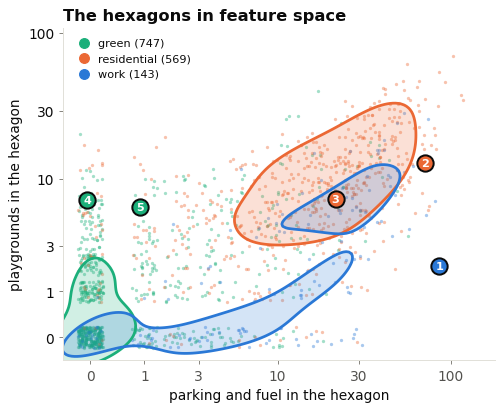

In [22]:
pairs = []
for i in range(len(FEATURES)):
    for j in range(i + 1, len(FEATURES)):
        rule = LogisticRegression(max_iter=2000).fit(X[:, [i, j]], y)
        pairs.append({"count 1": FEATURES[i], "count 2": FEATURES[j], "right": rule.score(X[:, [i, j]], y)})
pairs = pd.DataFrame(pairs).sort_values("right", ascending=False).reset_index(drop=True)
print(f"{len(pairs)} pairs of counts. Share of hexagons that a rule on the pair gets right: "
      f"best {pairs['right'].max():.0%}, median {pairs['right'].median():.0%}, worst {pairs['right'].min():.0%}.")
print(pairs.head(5).round(3).to_string())

two = [FEATURES.index("car"), FEATURES.index("play")]          # parking and fuel, playgrounds
names2 = ["parking and fuel in the hexagon", "playgrounds in the hexagon"]
rank = int(pairs.index[(pairs["count 1"] == "car") & (pairs["count 2"] == "play")][0]) + 1
print(f"\nparking and fuel + playgrounds: rank {rank} of {len(pairs)}")
h.note("pairs", {"n": len(pairs), "best": round(float(pairs['right'].max()), 3), "median": round(float(pairs['right'].median()), 3),
                 "rank_car_play": rank, "best_pair": [pairs.loc[0, "count 1"], pairs.loc[0, "count 2"]]}, SAVE)

fig, ax = plt.subplots(figsize=(6.2, 4.8))
h.feature_plane(X[:, two], y, names2, rows=FIVE, ax=ax, title="The hexagons in feature space")
h.save(fig, "0_feature_plane.png", SAVE, untitled=True)
plt.show()

Each shaded region holds the densest half of the hexagons of one land use. Green hexagons sit near zero on both axes. Residential hexagons have both parking and playgrounds, and work hexagons have parking with few playgrounds. The regions overlap, and no pair of counts changes that: the best of the 120 pairs gets three hexagons in four right. The dots are shifted by a small random amount, for drawing only, because counts are whole numbers and hundreds of hexagons would otherwise hide behind each other.

A third count adds a third axis. With offices as the third, the work hexagons rise above the others.

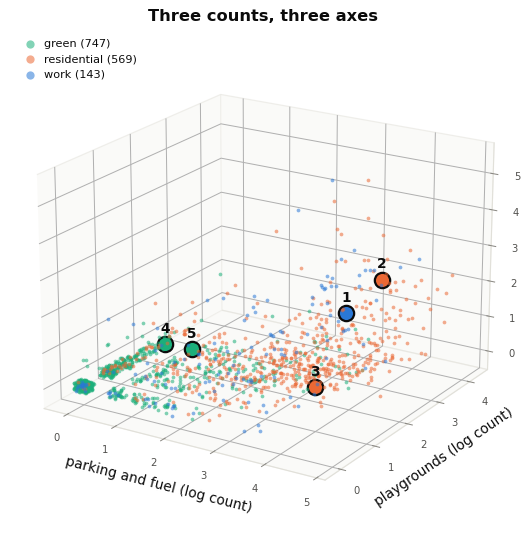

In [23]:
names3 = ["parking and fuel (log count)", "playgrounds (log count)", "offices (log count)"]
three = [FEATURES.index(f) for f in SHOW]

ax = h.feature_space(X[:, three], y, names3, rows=FIVE, title="Three counts, three axes")
h.save(ax.figure, "0_feature_space.png", SAVE)
plt.show()
if SAVE:    # a turning version, kept for those who want it on a slide
    h.spin_gif(lambda azim: h.feature_space(X[:, three], y, names3, rows=FIVE, azim=azim).figure, "0_feature_space.gif")

## 7. For a category, the rule is a boundary

Where the land uses sit in different parts of the plane, a rule can separate them. The same kind of rule as the line of step 4 now draws straight **boundaries**, and its parameters say where they run (the method is called logistic regression). The background colour is the rule's answer for every combination of the two counts.

hexagons on the right side of the boundaries: 75%     always answering 'green': 51%
the same rule with all 16 counts: 79%
parameters that place the boundaries: 9
share of each land use that the rule on two counts finds: green 85%, residential 76%, work 19%


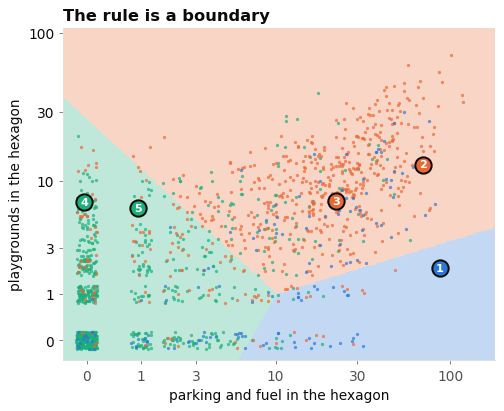

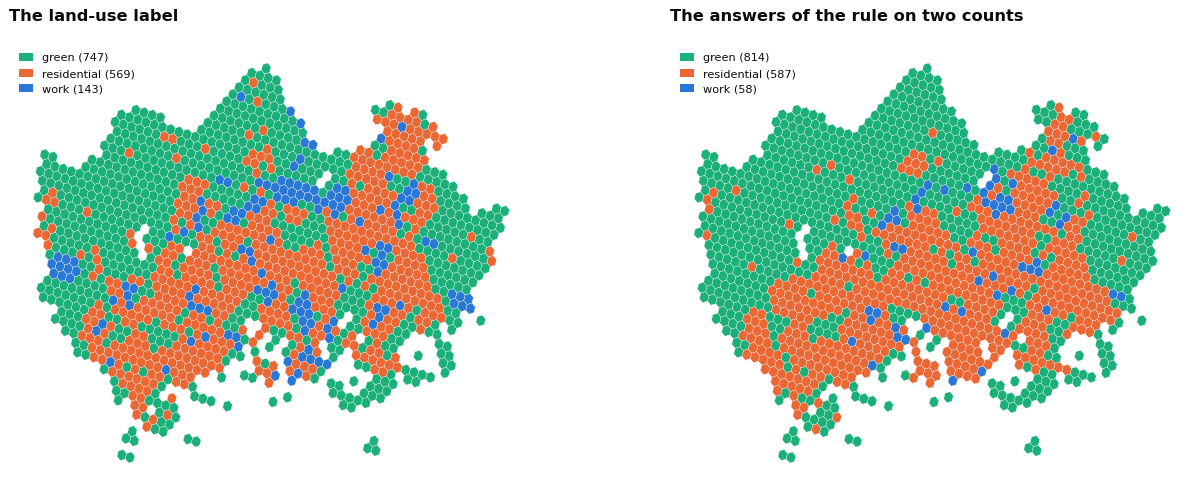

In [24]:
boundary = LogisticRegression(max_iter=2000).fit(X[:, two], y)
all_counts = LogisticRegression(max_iter=3000).fit(X, y)
answers = boundary.predict(X[:, two])
found = {c: float((answers[y == c] == c).mean()) for c in CLASSES}
print(f"hexagons on the right side of the boundaries: {boundary.score(X[:, two], y):.0%}     always answering 'green': {(y == 'green').mean():.0%}")
print(f"the same rule with all 16 counts: {all_counts.score(X, y):.0%}")
print(f"parameters that place the boundaries: {boundary.coef_.size + boundary.intercept_.size}")
print("share of each land use that the rule on two counts finds: " + ", ".join(f"{c} {v:.0%}" for c, v in found.items()))
h.note("boundary", {"two": round(float(boundary.score(X[:, two], y)), 3), "sixteen": round(float(all_counts.score(X, y)), 3),
                    "green": round(float((y == 'green').mean()), 3), "parameters": int(boundary.coef_.size + boundary.intercept_.size),
                    "found": {c: round(v, 2) for c, v in found.items()}}, SAVE)

fig, ax = plt.subplots(figsize=(6.2, 4.8))
h.regions(boundary, X[:, two], y, names2, ax=ax, title="The rule is a boundary", rows=FIVE, counts=(0, 1, 3, 10, 30, 100))
h.save(fig, "0_rule_boundary.png", SAVE, untitled=True)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
h.map_classes(hexes, y, ax=axes[0], title="The land-use label", places=False)
h.map_classes(hexes, answers, ax=axes[1], title="The answers of the rule on two counts", places=False)
plt.tight_layout()
plt.show()
if SAVE:
    fig = h.inset_map(hexes, labels=answers, rows=FIVE)
    h.save(fig, "0_inset_rule.png")
    plt.close(fig)

On the map the rule recovers the large green areas and the residential core, and it fails to find most work areas: two counts are not enough to tell them from residential ones. With all 16 counts the same kind of rule draws its boundaries in a space of 16 axes, which nobody can draw and which works in the same way.

## 8. Why a model is scored on rows it has not seen

Both rules above were fitted and scored on the same rows. That flatters them. To see by how much, we set a fifth of the rows aside before fitting, and compare two models on the rows they learned from and on the rows that were set aside. The first is the boundary rule with all 16 counts. The second is a model that memorises: a decision tree that keeps splitting until it answers every one of its own rows correctly.

In [25]:
def three_piles(seed):
    """Deal the hexagons at random into training (60%), validation (20%) and test (20%)."""
    rest, test = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=seed)
    train, valid = train_test_split(rest, test_size=0.25, stratify=y[rest], random_state=seed)
    return train, valid, test


scores = []
for seed in range(20):
    tr, va, te = three_piles(seed)
    memoriser = DecisionTreeClassifier(random_state=0).fit(X[tr], y[tr])
    rule = LogisticRegression(max_iter=3000).fit(X[tr], y[tr])
    scores.append({"memoriser, seen": memoriser.score(X[tr], y[tr]), "memoriser, unseen": memoriser.score(X[te], y[te]),
                   "rule, seen": rule.score(X[tr], y[tr]), "rule, unseen": rule.score(X[te], y[te])})
scores = pd.DataFrame(scores).mean()
print("share of hexagons answered correctly (means of 20 deals)")
print(scores.map("{:.0%}".format).to_string())
h.note("unseen", {k: round(float(v), 3) for k, v in scores.items()}, SAVE)

share of hexagons answered correctly (means of 20 deals)
memoriser, seen      97%
memoriser, unseen    72%
rule, seen           80%
rule, unseen         79%


> **What did we just see?** On its own rows the memoriser looks far better than the rule. On rows it has not seen it is worse. A score on the rows a model learned from mostly shows how well the model remembers, so it cannot be used to choose between models. (The memoriser does not reach 100% even on its own rows, because some hexagons have identical counts and different labels.)

## 9. Three piles of data

Hence the rows are dealt into piles at random before any learning, and for a reason explained in the next step there are three of them.

- **Training** (60%): the parameters are fitted on these rows.
- **Validation** (20%): we use these rows to choose between versions of the model.
- **Test** (20%): we look at these rows once, at the end. They are the unseen rows.

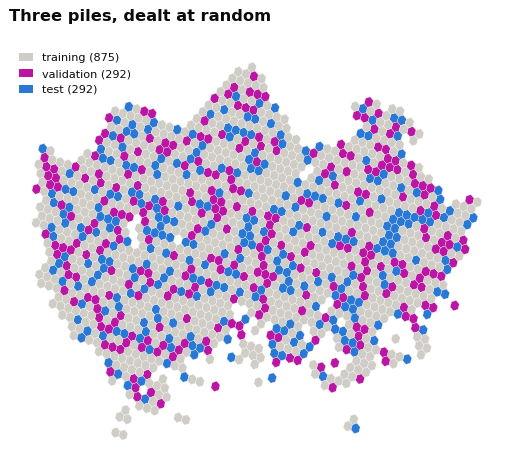

99% of the test hexagons touch at least one training hexagon.


In [26]:
p_train, p_valid, p_test = three_piles(SEED)
piles = np.full(len(y), "training", dtype=object)
piles[p_valid], piles[p_test] = "validation", "test"

fig, ax = plt.subplots(figsize=(8.6, 6))
h.map_piles(hexes, piles, ax=ax, title="Three piles, dealt at random")
h.save(fig, "0_three_piles.png", SAVE)
plt.show()

touching = np.mean([np.isin(W[i].indices, p_train).any() for i in p_test])
print(f"{touching:.0%} of the test hexagons touch at least one training hexagon.")
h.note("piles", {"training": len(p_train), "validation": len(p_valid), "test": len(p_test), "touching": round(float(touching), 2)}, SAVE)

On the map the three piles are thoroughly mixed, and almost every test hexagon touches a training hexagon. It does no harm here, and the page on challenges comes back to it.

## 10. One setting: how flexible may the rule be?

The parameters of a model are found by training. A model also has **settings** that we choose ourselves, before training (the technical word is hyperparameter). For a rule that predicts, the most important setting is how flexible it may be.

We take the regression task of step 3 and three rules: a flat line, a straight line, and a curve that may bend several times (a polynomial of degree 6). To make the point visible we give them little to learn from: 30 hexagons of the training pile.

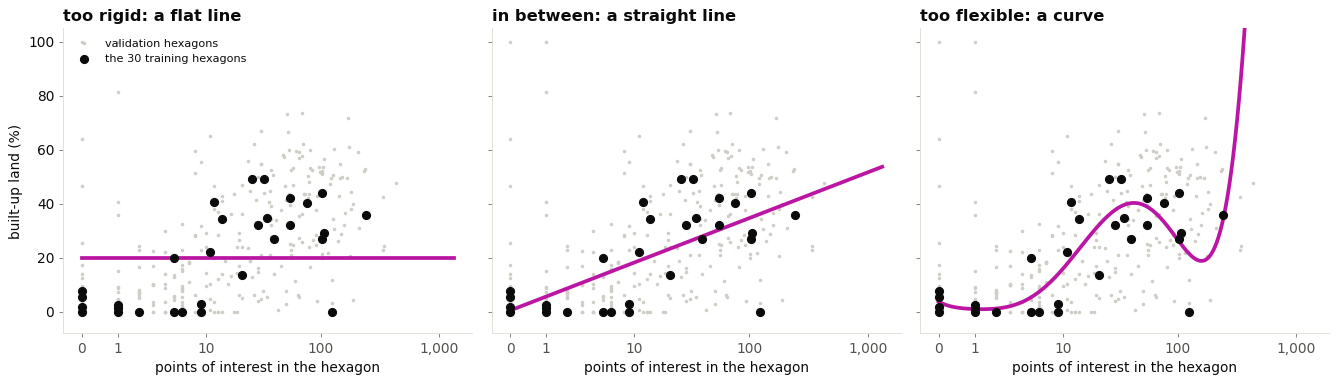

In [27]:
def curve(degree):
    """A polynomial of the given degree: 0 is a flat line, 1 a straight line, 6 a curve that may bend five times."""
    return make_pipeline(MinMaxScaler(), PolynomialFeatures(degree), LinearRegression())


def flex_axes(ax):
    h.count_ticks(ax, "x", [0, 1, 10, 100, 1000], lambda c: np.log10(1 + c))
    ax.set_ylim(-8, 105)
    ax.set_xlabel("points of interest in the hexagon")


few = np.random.default_rng(SEED).choice(p_train, 30, replace=False)       # 30 hexagons of the training pile
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, (degree, word) in zip(axes, {0: "too rigid: a flat line", 1: "in between: a straight line", 6: "too flexible: a curve"}.items()):
    m = curve(degree).fit(poi_log[few], built_up_pct[few])
    ax.scatter(poi_log[p_valid], built_up_pct[p_valid], s=8, color=h.PILES["training"], linewidths=0, label="validation hexagons")
    ax.scatter(poi_log[few], built_up_pct[few], s=40, color=h.INK, zorder=3, label="the 30 training hexagons")
    ax.plot(xs, np.clip(m.predict(xs), -40, 140), color=h.ACCENT, lw=3)
    flex_axes(ax)
    ax.set_title(word)
axes[0].set_ylabel("built-up land (%)")
axes[0].legend(loc="upper left", fontsize=9)
plt.tight_layout()
h.save(fig, "0_flexibility.png", SAVE)
plt.show()

In [28]:
DEGREES = [0, 1, 2, 3, 6, 9]
runs = []
for seed in range(200):                     # 200 deals of the piles, each with its own 30 training hexagons
    tr, va, te = three_piles(seed)
    few_tr = np.random.default_rng(seed).choice(tr, 30, replace=False)
    for degree in DEGREES:
        m = curve(degree).fit(poi_log[few_tr], built_up_pct[few_tr])
        runs.append({"seed": seed, "degree": degree, "training": m.score(poi_log[few_tr], built_up_pct[few_tr]),
                     "validation": m.score(poi_log[va], built_up_pct[va]), "test": m.score(poi_log[te], built_up_pct[te])})
runs = pd.DataFrame(runs)
print("R2, median of 200 deals (30 training hexagons each)")
print(runs.groupby("degree")[["training", "validation"]].median().round(2).to_string())

chosen = runs.loc[runs.groupby("seed")["validation"].idxmax()]
gentle = int((chosen["degree"] <= 3).sum())
print(f"\nThe degree that does best on validation is 1, 2 or 3 in {gentle} of 200 deals.")
print(f"The chosen rule: R2 {chosen['validation'].median():.2f} on the validation pile, {chosen['test'].median():.2f} on the test pile (medians).")
medians = runs.groupby("degree")[["training", "validation"]].median()


def draw_flex(degree):
    """One frame of the animation: the rule of this degree on the 30 hexagons, and its median scores over the 200 deals."""
    words = {0: "too rigid", 1: "in between", 2: "in between", 3: "in between", 6: "too flexible", 9: "much too flexible"}
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(9.6, 4.6), gridspec_kw={"width_ratios": [2.4, 1]})
    m = curve(degree).fit(poi_log[few], built_up_pct[few])
    ax.scatter(poi_log[p_valid], built_up_pct[p_valid], s=8, color=h.PILES["training"], linewidths=0)
    ax.scatter(poi_log[few], built_up_pct[few], s=40, color=h.INK, zorder=3)
    ax.plot(xs, np.clip(m.predict(xs), -40, 140), color=h.ACCENT, lw=3.5)
    flex_axes(ax)
    ax.set_ylabel("built-up land (%)")
    ax.set_title(f"{words[degree]}  (may bend {max(degree - 1, 0)} times)" if degree > 1 else f"{words[degree]}  ({'a flat line' if degree == 0 else 'a straight line'})")
    tr, va = medians.loc[degree, "training"], medians.loc[degree, "validation"]
    bx.bar([0, 1], [max(tr, 0), max(va, 0)], color=[h.MUTED, h.ACCENT], width=0.6)
    bx.text(0, max(tr, 0) + 0.02, f"{tr:.2f}", ha="center", fontsize=12, fontweight="bold")
    bx.text(1, max(va, 0) + 0.02, f"{va:.2f}" if va > -0.1 else "below 0", ha="center", fontsize=12, fontweight="bold")
    bx.set_xticks([0, 1], ["its own\n30 hexagons", "validation\npile"])
    bx.set_ylim(0, 0.75)
    bx.set_title("R²")
    bx.tick_params(axis="x", length=0)
    fig.tight_layout()
    return fig


if SAVE:    # the animation for the slides
    h.frames_gif(draw_flex, DEGREES, "0_flexibility.gif", ms=1400)
    h.frames(draw_flex, DEGREES, "flexibility")

big = curve(6).fit(poi_log[p_train], built_up_pct[p_train])
big_line = curve(1).fit(poi_log[p_train], built_up_pct[p_train])
print(f"With all {len(p_train)} training hexagons the same curve of degree 6 reaches {big.score(poi_log[p_valid], built_up_pct[p_valid]):.2f} on validation, "
      f"the straight line {big_line.score(poi_log[p_valid], built_up_pct[p_valid]):.2f}.")
h.note("flexibility", {"training": {int(d): round(float(v), 2) for d, v in medians["training"].items()},
                       "validation": {int(d): round(float(v), 2) for d, v in medians["validation"].items()},
                       "gentle_of_200": gentle, "chosen_validation": round(float(chosen["validation"].median()), 2),
                       "chosen_test": round(float(chosen["test"].median()), 2),
                       "all_rows_curve": round(float(big.score(poi_log[p_valid], built_up_pct[p_valid])), 2),
                       "all_rows_line": round(float(big_line.score(poi_log[p_valid], built_up_pct[p_valid])), 2)}, SAVE)

R2, median of 200 deals (30 training hexagons each)
        training  validation
degree                      
0           0.00       -0.02
1           0.40        0.35
2           0.43        0.33
3           0.47        0.33
6           0.53       -0.04
9           0.59     -103.37

The degree that does best on validation is 1, 2 or 3 in 194 of 200 deals.
The chosen rule: R2 0.36 on the validation pile, 0.34 on the test pile (medians).


With all 875 training hexagons the same curve of degree 6 reaches 0.31 on validation, the straight line 0.29.


<div class="frames" data-name="flexibility" data-labels="a flat line|a straight line|may bend once|may bend twice|may bend 5 times|may bend 8 times"></div>

*From a rigid rule to a flexible one, each fitted to the same 30 hexagons (black). The bars are R² on its own 30 hexagons and on the validation pile.*

> **What did we just see?** The flat line is too rigid: it explains nothing, on the rows it has seen and on new ones alike. This is called underfitting. The curve is too flexible: it follows its 30 hexagons more closely than the straight line does, and on new hexagons it is about as bad as the flat line. This is called overfitting, and it is the memoriser of step 8 again. The training rows cannot tell us which rule is best, since they always prefer the most flexible one; the validation pile can. And because we pick the rule that looks best on validation, a third pile, the test pile, is kept for an honest last look. Flexibility hurts when the rows are few: with the whole training pile the same curve does no harm.

# Semi-supervised learning: few labels

<div class="roadmap"><div class="rm-sofar"><span>So far</span>A rule needs rows with known answers, and such answers are slow and costly to collect.</div><div class="rm-question"><b>What can be learned when answers are scarce?</b><span>Semi-supervised learning: a model trained on 30 labelled rows labels the other 1,429 itself (self-training).</span></div><div class="rm-steps"><div class="rm-step"><b>Which 30?</b><span>at random, or ten per class</span></div><div class="rm-step"><b>Self-training</b><span>the model labels the rest, in a loop</span></div><div class="rm-step"><b>The result</b><span>it depends on the 30</span></div><div class="rm-step"><b>Going deeper</b><span>when the repair fails</span></div></div></div>

Imagine the land-use label had to be collected by a field visit, and the budget covers 30 hexagons. A supervised model can only learn from those 30. A semi-supervised model also uses the POI profiles of the other 1,429, which cost nothing.

As on the pages before, **accuracy** means the share of hexagons whose label a model gets right, counted on hexagons whose label the model was not given.

## The experiment

**Which 30?** There are two obvious ways to choose them.

- **30 at random**, as a survey with no prior knowledge would draw them.
- **10 per class**, which guarantees examples of the rare class but presupposes that we already know roughly where each class is, for example from an older map.

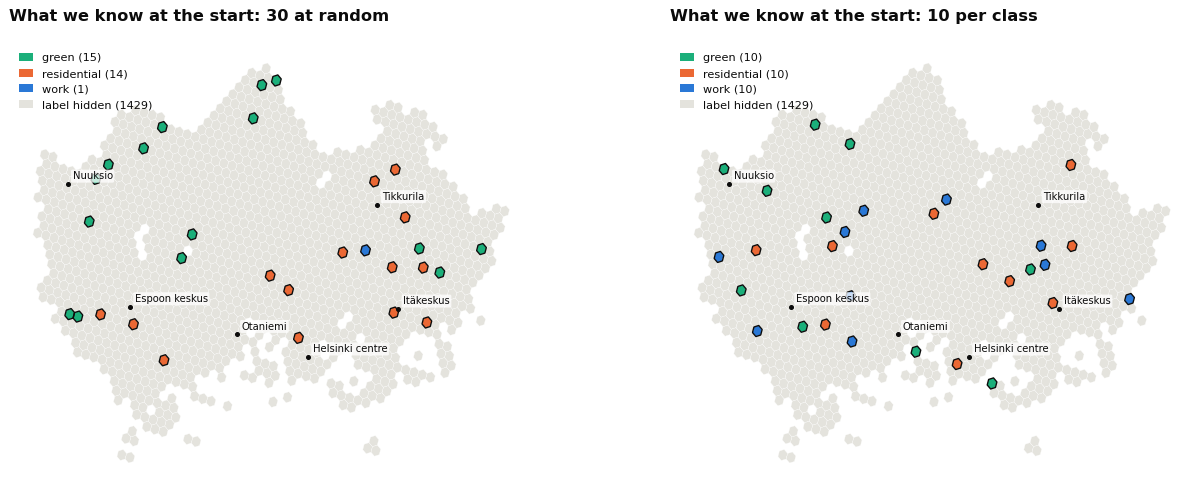

True shares of the classes: {'green': 51, 'residential': 39, 'work': 10}


In [29]:
N_LABELS = 30       # try 15, 60, 150
THRESHOLD = 0.80    # how sure the model must be before we believe its own prediction


def draw_labelled(seed, per_class):
    r = np.random.default_rng(seed)
    if per_class:
        return np.concatenate([r.choice(np.where(y == c)[0], N_LABELS // 3, replace=False) for c in CLASSES])
    return r.choice(len(y), N_LABELS, replace=False)


def hide_all_but(labelled):
    y_start = np.full(len(y), None, dtype=object)
    y_start[labelled] = y[labelled]
    return y_start


samples = {"30 at random": draw_labelled(SEED, per_class=False), "10 per class": draw_labelled(SEED, per_class=True)}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
for ax, (name, labelled) in zip(axes, samples.items()):
    h.map_classes(hexes, hide_all_but(labelled), ax=ax, outline=labelled, title=f"What we know at the start: {name}")
plt.tight_layout()
h.save(fig, "1_two_samples.png", SAVE)
plt.show()
print("True shares of the classes:", (pd.Series(y).value_counts(normalize=True).reindex(CLASSES) * 100).round(0).astype(int).to_dict())

**Self-training** is a loop:

1. train a model on the labelled hexagons,
2. let it predict the unlabelled ones,
3. keep the predictions it is very sure about and treat them as labels,
4. repeat.

The model is the boundary rule of the page on supervised learning (logistic regression). Each hexagon is described by its own POI profile and by its neighbours' profile (`X` and `X_around` side by side). Standardising the features needs no labels, so we standardise them once on all hexagons.

In [30]:
Z = StandardScaler().fit_transform(np.hstack([X, X_around]))


def new_model(C=1.0):
    return LogisticRegression(max_iter=2000, C=C)       # C is scikit-learn's default strength; smaller = more cautious


def self_train(F, y_start, threshold=0.80, C=1.0, max_rounds=40):
    """y_start holds a class name where the label is known and None where it is hidden.
    Returns the final model and a list with the label array after every round."""
    y_now = y_start.copy()
    history = [y_now.copy()]
    for _ in range(max_rounds):
        known = pd.notna(y_now)
        if known.all():
            break
        model = new_model(C).fit(F[known], y_now[known].astype(str))     # 1. train on what we have
        proba = model.predict_proba(F[~known])                           # 2. predict the rest
        sure = proba.max(axis=1) >= threshold                            # 3. keep the confident predictions
        if not sure.any():
            break
        y_now[np.where(~known)[0][sure]] = model.classes_[proba.argmax(axis=1)[sure]]
        history.append(y_now.copy())                                     # 4. repeat
    known = pd.notna(y_now)
    return new_model(C).fit(F[known], y_now[known].astype(str)), history

In [31]:
runs = {}
for name, labelled in samples.items():
    y_start = hide_all_but(labelled)
    hidden = pd.isna(y_start)
    supervised = new_model().fit(Z[labelled], y[labelled])
    model_self, history = self_train(Z, y_start, THRESHOLD)
    runs[name] = dict(labelled=labelled, y_start=y_start, hidden=hidden, history=history,
                      pred_supervised=supervised.predict(Z), pred_self=model_self.predict(Z))
    acc_sup = (runs[name]["pred_supervised"][hidden] == y[hidden]).mean()
    acc_self = (runs[name]["pred_self"][hidden] == y[hidden]).mean()
    runs[name].update(acc_supervised=acc_sup, acc_self=acc_self)
    print(f"{name}:  supervised {acc_sup:.1%}   self-training {acc_self:.1%}   ({len(history) - 1} rounds)")
print(f"Always guessing the largest class: {(y == 'green').mean():.1%}\n")

run = runs["30 at random"]
labelled, y_start, hidden, history = run["labelled"], run["y_start"], run["hidden"], run["history"]
print("Round by round, for the 30 hexagons drawn at random:")
for r, y_r in enumerate(history):
    adopted = pd.notna(y_r) & hidden
    note = f"of the adopted labels {(y_r[adopted] == y[adopted]).mean():.0%} are right" if adopted.any() else "the labels we were given"
    print(f"  round {r:2d}: {pd.notna(y_r).sum():5d} hexagons carry a label; {note}")

30 at random:  supervised 72.6%   self-training 72.7%   (8 rounds)


10 per class:  supervised 71.8%   self-training 76.3%   (11 rounds)
Always guessing the largest class: 51.2%

Round by round, for the 30 hexagons drawn at random:
  round  0:    30 hexagons carry a label; the labels we were given
  round  1:  1238 hexagons carry a label; of the adopted labels 76% are right
  round  2:  1378 hexagons carry a label; of the adopted labels 74% are right
  round  3:  1405 hexagons carry a label; of the adopted labels 74% are right
  round  4:  1414 hexagons carry a label; of the adopted labels 73% are right
  round  5:  1421 hexagons carry a label; of the adopted labels 73% are right
  round  6:  1424 hexagons carry a label; of the adopted labels 73% are right
  round  7:  1425 hexagons carry a label; of the adopted labels 73% are right
  round  8:  1426 hexagons carry a label; of the adopted labels 73% are right


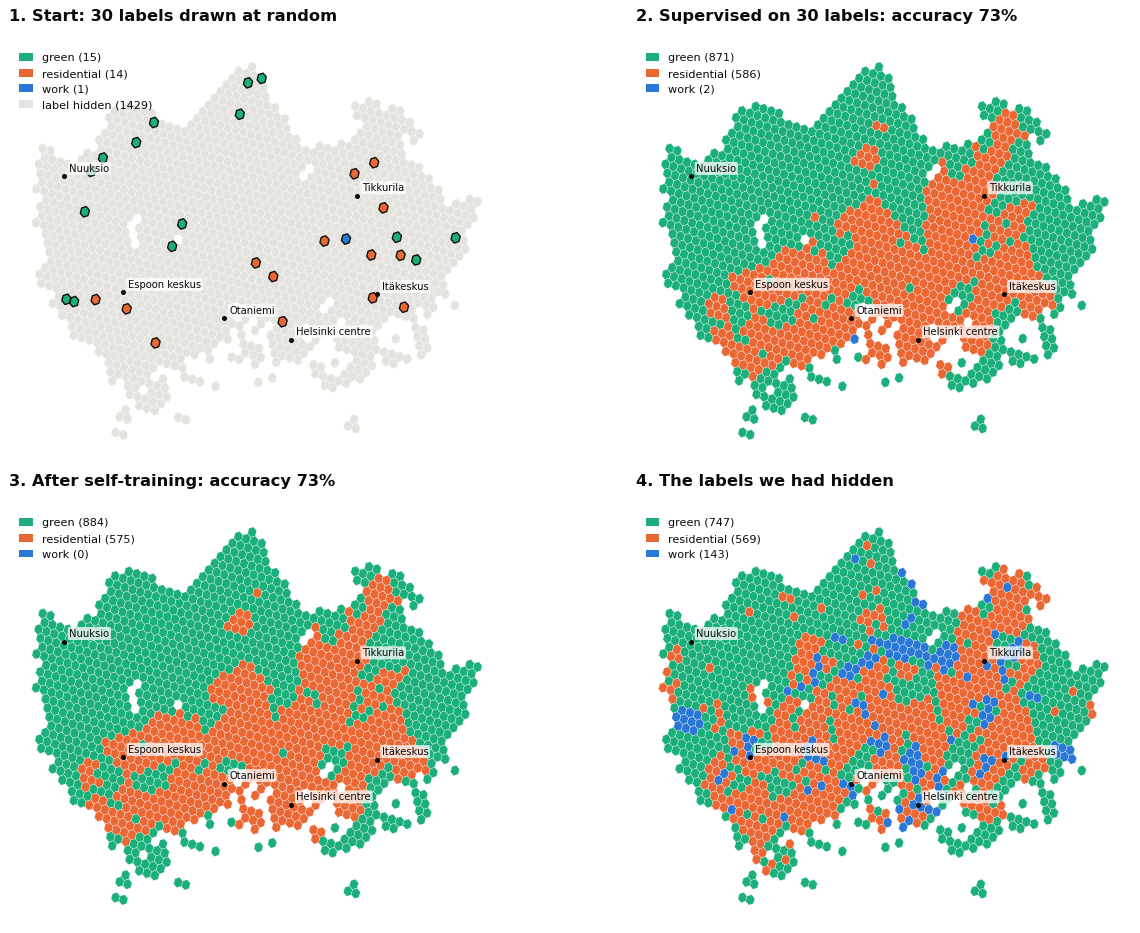

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10.5))
h.map_classes(hexes, y_start, ax=axes[0, 0], title=f"1. Start: {N_LABELS} labels drawn at random", outline=labelled)
h.map_classes(hexes, run["pred_supervised"], ax=axes[0, 1], title=f"2. Supervised on {N_LABELS} labels: accuracy {run['acc_supervised']:.0%}")
h.map_classes(hexes, run["pred_self"], ax=axes[1, 0], title=f"3. After self-training: accuracy {run['acc_self']:.0%}")
h.map_classes(hexes, y, ax=axes[1, 1], title="4. The labels we had hidden")
plt.tight_layout()
h.save(fig, "1_selftraining_four_maps.png", SAVE)
plt.show()

Round by round, more hexagons carry a label. Grey hexagons have none yet.

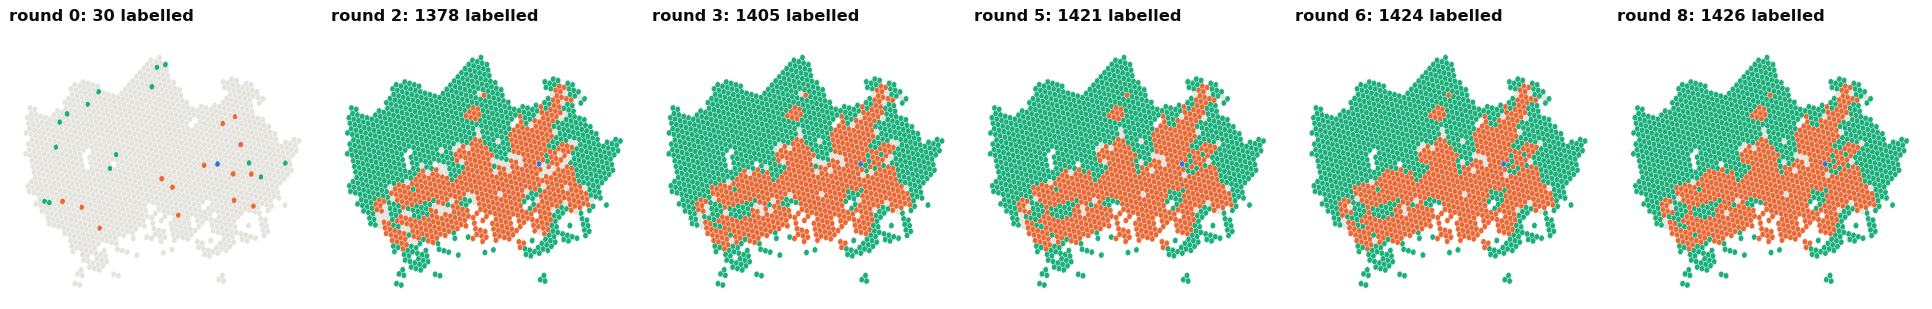

In [33]:
show = sorted(set(np.linspace(0, len(history) - 1, 6).round().astype(int)))
fig, axes = plt.subplots(1, len(show), figsize=(3.6 * len(show), 3.4))
for ax, r in zip(np.atleast_1d(axes), show):
    h.map_classes(hexes, history[r], ax=ax, places=False, legend=False,
                  title=f"round {r}: {pd.notna(history[r]).sum()} labelled")
plt.tight_layout()
h.save(fig, "1_selftraining_rounds.png", SAVE)
plt.show()

<div class="frames" data-name="selftraining" data-prefix="round" data-first="0"></div>

*Self-training, round by round. Grey hexagons have no label yet; outlined hexagons are the 30 we started with.*

> **What did we just see?** The model started from 30 labels, adopted its own most confident predictions, retrained, and went on to less certain hexagons. Three things are worth noticing.
>
> - After seeing only 30 labels, the model is already at least 80% sure about most of the hexagons, and it is wrong about roughly one in four of those. Being confident is not the same as being right, and the wrong labels become training data in the next round.
> - The newly labelled hexagons appear all over the map from the first round. Self-training moves through the *features*, from hexagons that look like a labelled one to hexagons that look less like it, and not outward across the map.
> - Compare the two samples in the printed lines above. The method is the same and the result is not. The next section asks why.

## Going deeper

**One draw is an anecdote.** We repeat the experiment with twelve different sets of 30 hexagons for each way of choosing them, and we record how often each model predicts the rare class, `work`.

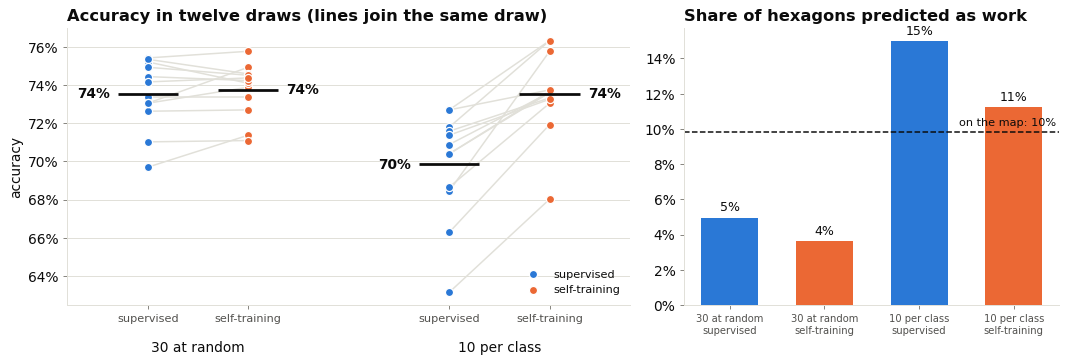

,supervised,self-training,"work, supervised","work, self-training"
sample,,,,
30 at random,73.5,73.8,5.0,3.6
10 per class,69.9,73.6,15.0,11.2


In [34]:
def one_draw(seed, per_class):
    lab = draw_labelled(seed, per_class)
    start = hide_all_but(lab)
    hid = pd.isna(start)
    sup = new_model().fit(Z[lab], y[lab]).predict(Z[hid])
    st = self_train(Z, start, THRESHOLD)[0].predict(Z[hid])
    return {"supervised": (sup == y[hid]).mean(), "self-training": (st == y[hid]).mean(),
            "work, supervised": (sup == "work").mean(), "work, self-training": (st == "work").mean()}


draws = pd.DataFrame([{"sample": name, "seed": s, **one_draw(s, per_class)}
                      for name, per_class in (("30 at random", False), ("10 per class", True)) for s in range(12)])
means = draws.groupby("sample", sort=False).mean(numeric_only=True).drop(columns="seed")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
for g, (name, part) in enumerate(draws.groupby("sample", sort=False)):
    x0, x1 = g * 3, g * 3 + 1
    for _, row in part.iterrows():
        ax.plot([x0, x1], [row["supervised"], row["self-training"]], color=h.GRID, linewidth=1.2, zorder=1)
    ax.scatter(np.full(len(part), x0), part["supervised"], s=42, color="#2a78d6", edgecolor="white", linewidth=1, zorder=3, label="supervised" if g == 0 else None)
    ax.scatter(np.full(len(part), x1), part["self-training"], s=42, color="#eb6834", edgecolor="white", linewidth=1, zorder=3, label="self-training" if g == 0 else None)
    for x, col, side in ((x0, "supervised", -1), (x1, "self-training", 1)):
        ax.hlines(part[col].mean(), x - 0.3, x + 0.3, color=h.INK, linewidth=2.2, zorder=4)
        ax.text(x + side * 0.38, part[col].mean(), f"{part[col].mean():.0%}", ha="right" if side < 0 else "left", va="center",
                fontsize=11, fontweight="bold", zorder=5)
    ax.text((x0 + x1) / 2, -0.13, name, ha="center", va="top", fontsize=11, transform=ax.get_xaxis_transform())
ax.set_xticks([0, 1, 3, 4], ["supervised", "self-training"] * 2, fontsize=9)
ax.set_xlim(-0.8, 4.8)
ax.set_ylabel("accuracy")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.yaxis.grid(True, color=h.GRID)
ax.set_title("Accuracy in twelve draws (lines join the same draw)")
ax.legend(loc="lower right", fontsize=9)

ax = axes[1]
labels = ["30 at random\nsupervised", "30 at random\nself-training", "10 per class\nsupervised", "10 per class\nself-training"]
values = [means.loc["30 at random", "work, supervised"], means.loc["30 at random", "work, self-training"],
          means.loc["10 per class", "work, supervised"], means.loc["10 per class", "work, self-training"]]
ax.bar(range(4), values, width=0.6, color=["#2a78d6", "#eb6834", "#2a78d6", "#eb6834"])
for i, v in enumerate(values):
    ax.text(i, v + 0.004, f"{v:.0%}", ha="center", fontsize=10)
true_work = (y == "work").mean()
ax.axhline(true_work, color=h.INK, linestyle="--", linewidth=1.2)
ax.text(3.45, true_work + 0.004, f"on the map: {true_work:.0%}", ha="right", fontsize=9)
ax.set_xticks(range(4), labels, fontsize=8)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Share of hexagons predicted as work")
plt.tight_layout()
h.save(fig, "1_two_designs.png", SAVE)
plt.show()
(means * 100).round(1)

> **What did we just see?** With 30 hexagons drawn at random, self-training changes little: some draws go up, some go down. With ten per class it gains in almost every draw. The right-hand chart shows the reason. Ten per class makes a third of the labelled hexagons `work`, although about a tenth of the map is. The supervised model learns those proportions and predicts `work` too often. The unlabelled hexagons pull the proportions back towards those of the map.
>
> So self-training did not discover new knowledge here. It repaired a labelled sample that misrepresented the map, and a sample that represents the map needed no repair. Neither sample is simply better: the random one matches the class proportions and may contain a single `work` hexagon, while ten per class guarantees examples of the rare class and distorts the proportions. Which one you want depends on what the map is for.

**How fragile is the repair?** The gain above belongs to one model. Logistic regression has a setting, `C`, for how strongly it trusts its training data; we used scikit-learn's default. A more cautious model (`C = 0.1`) is a sensible choice with 30 labels and 32 features. What happens then?

In [35]:
rows = []
for C, model_name in ((1.0, "default (C = 1)"), (0.1, "more cautious (C = 0.1)")):
    for sample, per_class in (("30 at random", False), ("10 per class", True)):
        sup, st, wrong = [], [], []
        for s in range(12):
            lab = draw_labelled(s, per_class)
            start = hide_all_but(lab)
            hid = pd.isna(start)
            sup.append((new_model(C).fit(Z[lab], y[lab]).predict(Z[hid]) == y[hid]).mean())
            model, hist = self_train(Z, start, THRESHOLD, C=C)
            st.append((model.predict(Z[hid]) == y[hid]).mean())
            adopted = pd.notna(hist[-1]) & hid
            wrong.append((hist[-1][adopted] != y[adopted]).mean())
        rows.append({"model": model_name, "sample": sample, "supervised": np.mean(sup), "self-training": np.mean(st),
                     "worst draw, self-training": np.min(st), "adopted labels that are wrong": np.mean(wrong)})
fragile = pd.DataFrame(rows).set_index(["model", "sample"])
(fragile * 100).round(1)

supervised  self-training  \
model                   sample                                    
default (C = 1)         30 at random        73.5           73.8   
                        10 per class        69.9           73.6   
more cautious (C = 0.1) 30 at random        73.3           73.0   
                        10 per class        74.2           44.8   

                                      worst draw, self-training  \
model                   sample                                    
default (C = 1)         30 at random                       71.1   
                        10 per class                       68.0   
more cautious (C = 0.1) 30 at random                       70.0   
                        10 per class                       36.5   

                                      adopted labels that are wrong  
model                   sample                                       
default (C = 1)         30 at random                           25.0  
                        10 per class                           24.8  
more cautious (C = 0.1) 30 at random                           24.6  
                        10 per class                           54.6

> **What did we just see?** With ten labels per class, the more cautious model is as accurate *without* any unlabelled hexagon as the default model is after self-training. So the repair was needed by one model, not by the sample as such. And when the cautious model is self-trained, it collapses: more than half of the labels it adopts are wrong, and each round trains on the mistakes of the round before.
>
> Self-training is fragile. On this dataset its outcome depended on how the 30 hexagons were chosen, on the threshold and on a setting of the model, and it ranged from a gain of a few points to a collapse. Unlabelled data are no free lunch: test the method on your own data before you trust it.

**Geography alone.** The opposite extreme: ignore the POIs entirely and let each labelled hexagon pass its label to its neighbours, who pass it on to theirs. This is *label propagation* on the hexagon grid, using only `W`.

Label propagation from 30 random labels, geography only: accuracy 61.9% in this draw, 55.6% on average over twelve draws (always guessing green: 51.2%)


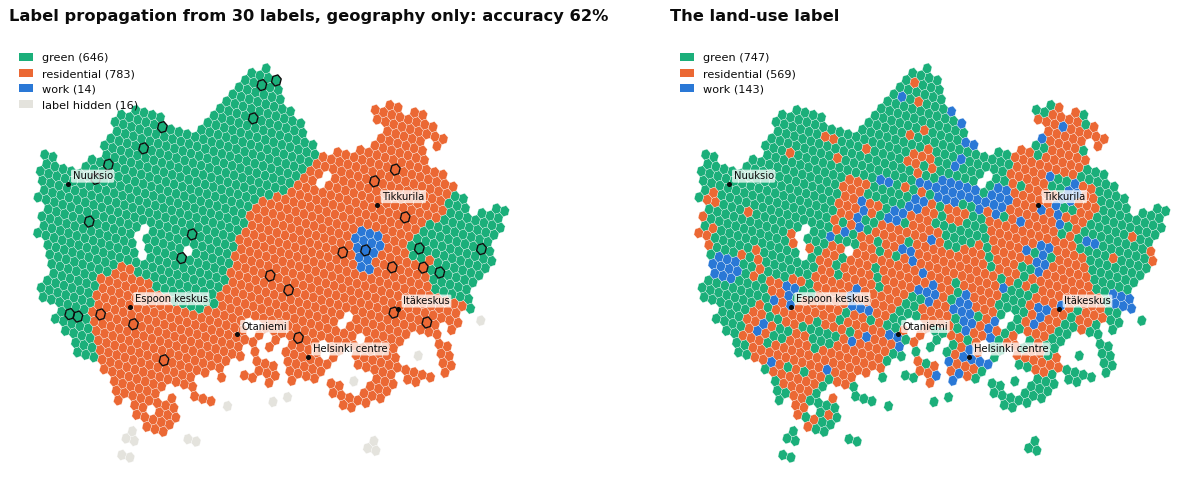

In [36]:
def propagate(y_start, W, rounds=300, keep=0.9):
    start = np.stack([(y_start == c).astype(float) for c in CLASSES], axis=1)   # one column per class
    score = start.copy()
    for _ in range(rounds):
        score = keep * (W @ score) + (1 - keep) * start      # take the neighbours' average, keep the known labels
    pred = np.array(CLASSES, dtype=object)[score.argmax(axis=1)]
    pred[score.sum(axis=1) == 0] = None                      # hexagons no label ever reached
    return pred


pred_geo = propagate(y_start, W)
acc_geo = (pred_geo[hidden] == y[hidden]).mean()
acc_geo_draws = [np.mean(propagate(hide_all_but(lab), W)[np.setdiff1d(np.arange(len(y)), lab)] == np.delete(y, lab))
                 for lab in (draw_labelled(s, False) for s in range(12))]
print(f"Label propagation from {N_LABELS} random labels, geography only: accuracy {acc_geo:.1%} in this draw, "
      f"{np.mean(acc_geo_draws):.1%} on average over twelve draws (always guessing green: {(y == 'green').mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
h.map_classes(hexes, pred_geo, ax=axes[0], outline=labelled,
              title=f"Label propagation from {N_LABELS} labels, geography only: accuracy {acc_geo:.0%}")
h.map_classes(hexes, y, ax=axes[1], title="The land-use label")
plt.tight_layout()
h.save(fig, "1_label_propagation.png", SAVE)
plt.show()

> **What did we just see?** Each labelled hexagon grows a territory around itself, like a Voronoi diagram (week 6). With 30 labels on 1,459 hexagons the territories are far too coarse: on average the result is only a few points better than always guessing `green`, and well below the supervised model that uses the POIs. Spatial dependence is real, and it is still not enough by itself here: adjacent hexagons are alike, but 30 seeds cannot know where the forest ends. In the notebook, set `N_LABELS = 300` and run the cells of this page again.

## Your turn

- Change `N_LABELS` to 15, 60 and 150 and run the cells of this page again. Does the difference between the two samples remain?
- Set `THRESHOLD = 0.5`, then `0.95`. What happens to the number of rounds and to the share of adopted labels that are right?
- Repair the ten-per-class sample without self-training: give each labelled hexagon a weight equal to its class's share on the map (`new_model().fit(Z[lab], y[lab], sample_weight=...)`). How close does the supervised model come to the self-trained one? In practice, where would those shares come from?
- Describe each hexagon by its own profile alone: replace `Z` by `StandardScaler().fit_transform(X)`. What changes?
- Label propagation and self-training use different information. Can you combine them, for example by adding the propagated scores as extra features?

**Ask an AI assistant**

> I have a NumPy feature matrix `Z` (n × 32), an array `y_start` with class names for 30 rows and `None` elsewhere, and a function `self_train(Z, y_start, threshold)` that returns `(model, history)`. Write a short loop that runs it for thresholds 0.5 to 0.95 and plots the final accuracy on the hidden rows, where the full labels are in `y`. Use matplotlib only.

Then check its answer: does it measure accuracy only on the rows that were hidden at the start?

# Self-supervised learning: no labels

<div class="roadmap"><div class="rm-sofar"><span>So far</span>With 30 labels, the unlabelled rows repaired a skewed sample and added little otherwise.</div><div class="rm-question"><b>Can a model learn what places are like when nobody tells it anything?</b><span>Self-supervised learning: the model predicts one part of the data from another (a pretext task) and keeps the description it had to form (an embedding).</span></div><div class="rm-steps"><div class="rm-step"><b>Pretext task</b><span>guess the neighbours of a hexagon</span></div><div class="rm-step"><b>Embedding</b><span>a place as 8 numbers</span></div><div class="rm-step"><b>Similar places</b><span>which hexagons are most like Otaniemi?</span></div><div class="rm-step"><b>Going deeper</b><span>does it help prediction?</span></div></div></div>

Self-training passes labels along the features, so it can only be as good as those features are at placing similar hexagons together. Can such features be learned before any label exists? The trick of self-supervised learning is to invent a task whose answers are already in the data, a *pretext task*. Ours:

> *From a hexagon's own POI profile, guess its neighbours' profile.*

Nobody labelled anything. The target is `W @ X`, the spatial lag of week 3. The model that learns this task is a small neural network: layers of simple units, each of which passes numbers on to the next layer. To do well, the network has to work out what kind of place a hexagon is, because the same kinds of places tend to have the same kinds of surroundings. We force it to pass that knowledge through a narrow layer of 8 numbers. Those 8 numbers are the **embedding**.

## The experiment

In [37]:
own = StandardScaler().fit_transform(X)              # input: my own POI profile
around = StandardScaler().fit_transform(X_around)    # target: my neighbours' profile (no land-use label anywhere)

net = MLPRegressor(hidden_layer_sizes=(32, 8, 32), alpha=1e-3, max_iter=3000, random_state=SEED)
net.fit(own, around)
print(f"Pretext task, on the hexagons the network was trained on: R² = {net.score(own, around):.2f}")


def encode(net, inputs, layers=2):
    """Run the inputs through the first layers of the network and stop at the narrow 8-number layer."""
    a = inputs
    for weights, bias in list(zip(net.coefs_, net.intercepts_))[:layers]:
        a = np.maximum(a @ weights + bias, 0)        # ReLU
    return a


E = StandardScaler().fit_transform(encode(net, own))    # the embedding: 8 numbers per hexagon
print("Embedding of the Otaniemi hexagon:", np.round(E[q_otaniemi], 2))

Pretext task, on the hexagons the network was trained on: R² = 0.77
Embedding of the Otaniemi hexagon: [ 1.28 -0.58 -0.94  0.9  -0.28  2.94  1.29  2.23]


The numbers themselves mean nothing to us. What we hope is that **places that are alike end up close together**. If so, we can search: *which hexagons are most like Otaniemi?*

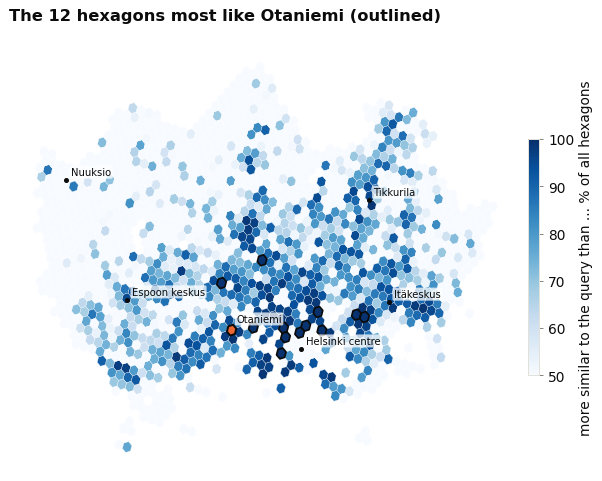

The query hexagon stands out for: culture, office, food, bike


,km from query,landmarks,poi_total,landuse,stands out for
0,6.2,Helsingin kaupunginteatteri; Eläintarhanlahden...,205,green,"culture, health, education, food"
1,8.0,Diakonia-ammattikorkeakoulu; Yrkeshögskolan Ar...,343,residential,"craft_industry, shop_daily, culture, office"
2,4.9,Kivelän sairaala; Töölön kirjasto,206,green,"lodging, culture, bike, shop_daily"
3,5.0,Kauppakeskus Ruoholahti; Biitsi Salmisaari,186,work,"finance, culture, shop_daily, craft_industry"
4,8.2,Redi; BioRex Redi,450,work,"culture, shop_daily, food, shop_other"
5,4.7,Meilahden sairaala-alue; Töölön uimahalli,317,residential,"culture, craft_industry, bike, office"
6,11.4,Noli Herttoniemi; Herttoniemen Montessori-leik...,123,residential,"lodging, culture, street_furniture, bike"
7,4.3,Laurea-ammattikorkeakoulu Leppävaaran kampus; ...,461,residential,"finance, shop_daily, food, shop_other"
8,12.1,"Careeria; Stadin Ammattiopisto, Abraham Wetter...",117,work,"culture, food, shop_other, civic"
9,6.9,Kannelmäen kirjasto; Kannelmäen liikuntapuisto,257,residential,"culture, health, shop_other, shop_daily"


In [38]:
def most_similar(M, query, k=12):
    distance = np.linalg.norm(M - M[query], axis=1)
    order = np.argsort(distance)
    return order[order != query][:k], distance


def stands_out(i, k=4):
    """The k kinds of POI of which hexagon i has unusually many, compared with all hexagons."""
    return ", ".join(np.array(FEATURES)[np.argsort(-own[i])[:k]])


QUERY = q_otaniemi          # or: h.hexagon_at(hexes, lon, lat) for any place you like
top, distance = most_similar(E, QUERY)
closer_than = 100 * (1 - pd.Series(distance).rank(pct=True).to_numpy())     # 99 = among the 1 % most similar

fig, ax = plt.subplots(figsize=(9.5, 6.2))
h.map_values(hexes, closer_than, ax=ax, cmap="Blues", vmin=50, vmax=100,
             label="more similar to the query than ... % of all hexagons", outline=top,
             title=f"The {len(top)} hexagons most like Otaniemi (outlined)")
hexes.iloc[[QUERY]].plot(ax=ax, facecolor="#eb6834", edgecolor=h.INK, linewidth=1.6, zorder=5)
h.save(fig, "2_similarity_otaniemi.png", SAVE)
plt.show()

print("The query hexagon stands out for:", stands_out(QUERY))
table = hexes.iloc[top][["landmarks", "poi_total", "landuse"]].copy()
table.insert(0, "km from query", np.round(np.linalg.norm(xy[top] - xy[QUERY], axis=1) / 1000, 1))
table["stands out for"] = [stands_out(i) for i in top]
table.reset_index(drop=True)

> **What did we just see?** A model that was never given land use or place names can still answer "find me places like this one". The answers lie kilometres away from Otaniemi and none of them touches it. Read the column *stands out for* to see what they share with the query, and compare the land-use labels: similar surroundings and similar land use are not the same thing.
>
> Read the *landmarks* column with care. It lists a university or a shopping centre first whenever a hexagon contains one, so it can make any busy hexagon look like a campus.
>
> Searching in an embedding is the *geospatial similarity search* of the lecture. Large Earth observation models such as AlphaEarth Foundations apply the same idea at a much larger scale: 64 numbers for every 10 m pixel of the land surface and every year, learned from satellite and other Earth observation records.

## Going deeper

**Is the embedding different from the raw profile, and is it better?** Three checks. The second compares the embedding with a plain summary of the same size: the 8 principal components of the 16 counts (principal component analysis, PCA). The third is *slow* (about half a minute).

In [39]:
top_raw, _ = most_similar(own, QUERY)
print(f"1. The same search in the raw profile shares {len(set(top) & set(top_raw))} of {len(top)} hexagons with the search in the embedding.")


def like_with_like(M, k=6):
    """Share of the k most similar hexagons (in the space M) that carry the same land-use label."""
    idx = NearestNeighbors(n_neighbors=k + 1).fit(M).kneighbors(M)[1][:, 1:]
    return (y[idx] == y[:, None]).mean()


pca8 = StandardScaler().fit_transform(PCA(n_components=8, random_state=SEED).fit_transform(own))   # a plain 8-number summary
print("2. Share of the six most similar hexagons with the same land-use label:")
for name, M in (("raw POI profile (16 numbers)", own), ("PCA of the profile (8 numbers)", pca8), ("our embedding (8 numbers)", E)):
    print(f"     {name:32s} {like_with_like(M):.0%}")
print(f"     {'the adjacent hexagons on the map':32s} {same_as_neighbours:.0%}")

folds_r2 = []
for tr, te in GroupKFold(5).split(own, groups=KMeans(n_clusters=10, n_init=10, random_state=SEED).fit_predict(xy)):
    m = MLPRegressor(hidden_layer_sizes=(32, 8, 32), alpha=1e-3, max_iter=3000, random_state=SEED).fit(own[tr], around[tr])
    folds_r2.append(m.score(own[te], around[te]))
print(f"3. Pretext task: R² = {net.score(own, around):.2f} on the training hexagons, {np.mean(folds_r2):.2f} on held-out areas.")

1. The same search in the raw profile shares 1 of 12 hexagons with the search in the embedding.
2. Share of the six most similar hexagons with the same land-use label:
     raw POI profile (16 numbers)     72%
     PCA of the profile (8 numbers)   71%
     our embedding (8 numbers)        68%
     the adjacent hexagons on the map 69%


3. Pretext task: R² = 0.77 on the training hexagons, 0.31 on held-out areas.


> **What did we just see?** The network changed the answer: the two searches return mostly different hexagons. It did not make the answer better by the one yardstick we have, since hexagons that are close in the embedding share a land-use label slightly *less* often than hexagons that are close in the raw profile. And the network explains its own training hexagons much better than hexagons in areas it has not seen, which is a first taste of the page on challenges.
>
> So this demo shows that an embedding supports search. It does not show that this embedding is better than the counts it was built from.

**The embedding in two dimensions.** It never saw the labels. If we squash the 8 numbers to 2 for plotting and colour by land use afterwards, do the classes separate?

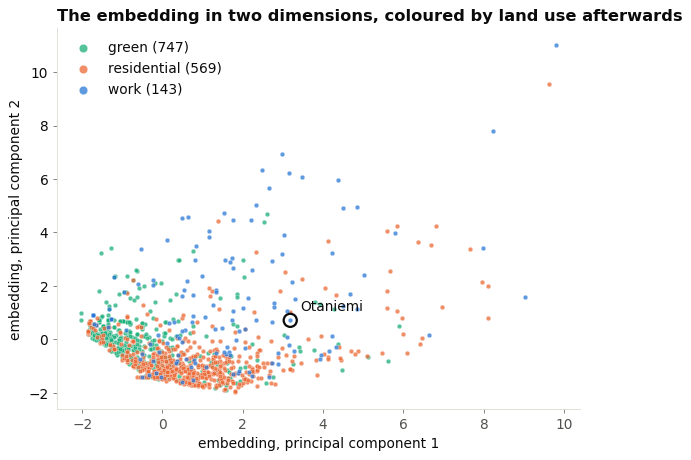

In [40]:
E2 = PCA(n_components=2, random_state=SEED).fit_transform(E)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for c in CLASSES:
    m = y == c
    ax.scatter(E2[m, 0], E2[m, 1], s=14, color=COLORS[c], alpha=0.75, edgecolor="white", linewidth=0.3, label=f"{c} ({m.sum()})")
ax.scatter(*E2[q_otaniemi], s=110, facecolor="none", edgecolor=h.INK, linewidth=1.8)
ax.annotate("Otaniemi", E2[q_otaniemi], xytext=(8, 8), textcoords="offset points")
ax.set_title("The embedding in two dimensions, coloured by land use afterwards")
ax.set_xlabel("embedding, principal component 1")
ax.set_ylabel("embedding, principal component 2")
ax.legend(markerscale=1.8)
h.save(fig, "2_embedding_2d.png", SAVE)
plt.show()

> **What did we just see?** Partly. Green hexagons crowd into one corner, work areas spread out towards the top and right, and residential hexagons sit in between and overlap both. The embedding has organised places by how much and what kind of activity they hold, which is related to land use without being the same thing.

**Pre-train, then fine-tune.** The reason to learn an embedding first is the *downstream task*: with a good representation, a handful of labels should go further. We return to 30 labels drawn at random and train the same classifier on three descriptions of a hexagon.

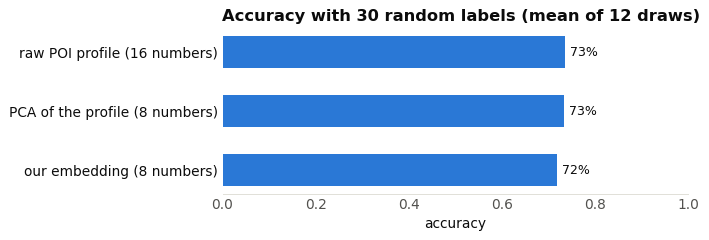

raw POI profile (16 numbers)     73.4%  (± 2.2% between draws)
PCA of the profile (8 numbers)   73.2%  (± 1.9% between draws)
our embedding (8 numbers)        71.7%  (± 2.9% between draws)


In [41]:
def few_label_accuracy(M, seeds=range(12)):
    scores = []
    for seed in seeds:
        lab = draw_labelled(seed, per_class=False)
        rest = np.setdiff1d(np.arange(len(y)), lab)
        scores.append((new_model().fit(M[lab], y[lab]).predict(M[rest]) == y[rest]).mean())
    return np.mean(scores), np.std(scores)


options = {"raw POI profile (16 numbers)": own, "PCA of the profile (8 numbers)": pca8, "our embedding (8 numbers)": E}
results = {name: few_label_accuracy(M) for name, M in options.items()}

fig, ax = plt.subplots(figsize=(8, 2.8))
h.bars(ax, list(results), [m for m, s in results.values()], title="Accuracy with 30 random labels (mean of 12 draws)")
plt.tight_layout()
h.save(fig, "2_downstream_30_labels.png", SAVE)
plt.show()
for name, (m, s) in results.items():
    print(f"{name:32s} {m:.1%}  (± {s:.1%} between draws)")

> **What did we just see?** Read the numbers before believing the story. On a table this small and this simple, the learned embedding does not beat the raw counts, and the differences are of the same size as the spread between draws. The idea pays off when the raw input is huge and unstructured (a satellite image, a street-view photo, a sentence) and labelled examples are rare, which is the setting foundation models are built for. Even there the gain is not automatic: the AlphaEarth paper notes that learned features "don't always outperform designed featurization methods in scarce data regimes" (Brown et al., 2025).

## Your turn

- Change `QUERY` to another place: `h.hexagon_at(hexes, 24.941, 60.170)` is the city centre, `(25.082, 60.210)` Itäkeskus, `(24.550, 60.300)` Nuuksio. Do the answers make sense to you as someone who knows the region? Where do they not?
- Compare `most_similar(E, QUERY)` with `most_similar(own, QUERY)` for a place you know well. Which list would you trust more, and why?
- Change the width of the narrow layer from 8 to 2 or 32 in `hidden_layer_sizes`. What happens to the three checks under *Going deeper*?
- Change the pretext task: hide half of the 16 counts and ask the network to reconstruct them (a *masked* task, as in the S2Vec figure of the lecture).

**Going further with real tools**

- The Python library [`srai`](https://kraina-ai.github.io/srai/) has a ready `Hex2VecEmbedder` that learns hexagon embeddings from OpenStreetMap tags. It needs PyTorch (`pip install "srai[torch]"`) and its authors warn that it is under heavy development, so expect to read the documentation.
- The [AlphaEarth Satellite Embedding dataset](https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_SATELLITE_EMBEDDING_V1_ANNUAL) in Google Earth Engine gives 64 numbers per 10 m pixel for every year from 2017 to 2024 (licence CC BY 4.0). Averaging them per hexagon would give you a second, image-based embedding of the same hexagons to compare with this one.

**Ask an AI assistant**

> I have a GeoDataFrame `hexes` of H3 hexagons and a NumPy array `E` with one embedding row per hexagon. Write a function that takes a longitude and latitude, finds the hexagon containing that point, and returns the 10 most similar hexagons by cosine similarity with their `landmarks` column. Mind the coordinate reference system: `hexes` is in EPSG:3067.

Then check its answer: did it reproject the point before testing which hexagon contains it?

# Reinforcement learning: only rewards

<div class="roadmap"><div class="rm-sofar"><span>So far</span>In every method so far, the data existed before learning began.</div><div class="rm-question"><b>Can a machine learn by trying, as we do?</b><span>Reinforcement learning: act, receive a reward, and adjust what to do next.</span></div><div class="rm-steps"><div class="rm-step"><b>A courier robot</b><span>a depot, a customer, roadworks</span></div><div class="rm-step"><b>Points</b><span>+20 arriving, −10 roadworks, −1 a move</span></div><div class="rm-step"><b>300 tries</b><span>from wandering to the shortest route</span></div><div class="rm-step"><b>The words</b><span>agent, environment, state, action, reward</span></div></div></div>

Reinforcement learning is the one way of learning that has no table at all, and this page uses no hexagons. A courier robot stands at a depot in a small grid of streets and has to reach a customer. Nobody shows it a route. It only receives points: 20 for arriving, minus 10 for driving into roadworks, and minus 1 for every other move, so that short routes pay best.

In [42]:
COLS, ROWS = 7, 5
DEPOT, CUSTOMER = (0, 0), (6, 4)
ROADWORKS = {(2, 0), (2, 1), (2, 2), (4, 4), (4, 3), (4, 2)}
MOVES = [(0, 1), (1, 0), (0, -1), (-1, 0)]          # north, east, south, west


def drive(place, move):
    """What the street grid answers to one move: the new place, the points for it, and whether the robot has arrived."""
    nxt = (place[0] + MOVES[move][0], place[1] + MOVES[move][1])
    if nxt in ROADWORKS:
        return place, -10, False                        # drives into roadworks and stays where it was
    if not (0 <= nxt[0] < COLS and 0 <= nxt[1] < ROWS):
        return place, -1, False                         # the edge of the map: a wasted move
    return nxt, (20 if nxt == CUSTOMER else -1), nxt == CUSTOMER


def learn(tries=300, seed=0, max_moves=200):
    """Trial and error. The robot keeps one number for every place and move: the points it expects from there on.
    After each move it corrects that number a little (the method is called Q-learning)."""
    rng = np.random.default_rng(seed)
    expect = np.zeros((COLS, ROWS, 4))
    totals, routes = [], []
    for t in range(tries):
        curious = max(0.02, 1 - t / (0.6 * tries))     # share of moves made at random: high at first, then falling
        place, total, route = DEPOT, 0, [DEPOT]
        for _ in range(max_moves):
            move = int(rng.integers(4)) if rng.random() < curious else int(np.argmax(expect[place]))
            nxt, points, arrived = drive(place, move)
            best_next = 0.0 if arrived else expect[nxt].max()
            expect[place][move] += 0.5 * (points + 0.95 * best_next - expect[place][move])
            place, total = nxt, total + points
            route.append(place)
            if arrived:
                break
        totals.append(total)
        routes.append(route)
    return np.array(totals), routes, expect


def learned_route(expect, max_moves=60):
    """The route the robot drives when it always takes the move it expects most from."""
    place, route = DEPOT, [DEPOT]
    for _ in range(max_moves):
        place, _, arrived = drive(place, int(np.argmax(expect[place])))
        route.append(place)
        if arrived:
            break
    return route


totals, routes, expect = learn()
final = learned_route(expect)
print(f"try   1: {len(routes[0]) - 1:3d} moves, {totals[0]:+5d} points")
for t in (5, 20, 60, 150, 300):
    print(f"try {t:3d}: {len(routes[t - 1]) - 1:3d} moves, {totals[t - 1]:+5d} points")
print(f"after 300 tries, without random moves: {len(final) - 1} moves, {20 - (len(final) - 2):+d} points. The shortest safe route has 14 moves.")

repeats = np.array([len(learned_route(learn(seed=s)[2])) - 1 for s in range(50)])
print(f"Repeated 50 times with other random numbers: the learned route is the shortest possible in {int((repeats == 14).sum())} of 50.")
h.note("courier", {"first_moves": len(routes[0]) - 1, "first_points": int(totals[0]), "final_moves": len(final) - 1,
                   "final_points": 20 - (len(final) - 2), "shortest_in_50": int((repeats == 14).sum()), "tries": 300}, SAVE)

try   1: 152 moves,  -275 points
try   5: 114 moves,  -228 points
try  20: 166 moves,  -280 points
try  60:  28 moves,   -25 points
try 150:  19 moves,    +2 points
try 300:  14 moves,    +7 points
after 300 tries, without random moves: 14 moves, +7 points. The shortest safe route has 14 moves.


Repeated 50 times with other random numbers: the learned route is the shortest possible in 50 of 50.


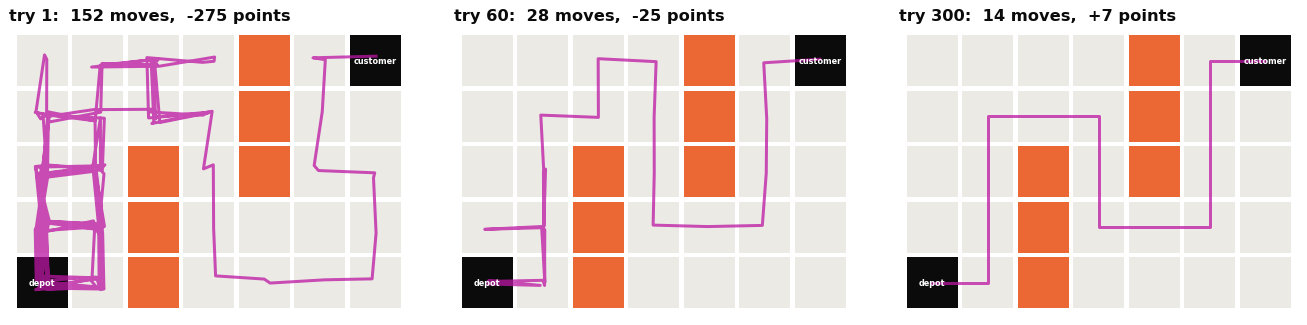

In [43]:
def draw_grid(ax, route=None, title=""):
    for col in range(COLS):
        for row in range(ROWS):
            works = (col, row) in ROADWORKS
            ax.add_patch(plt.Rectangle((col - 0.46, row - 0.46), 0.92, 0.92, fc="#eb6834" if works else "#eceae4", ec="none"))
    for (col, row), word in ((DEPOT, "depot"), (CUSTOMER, "customer")):
        ax.add_patch(plt.Rectangle((col - 0.46, row - 0.46), 0.92, 0.92, fc=h.INK, ec="none"))
        ax.text(col, row, word, color="white", ha="center", va="center", fontsize=6.5, fontweight="bold", zorder=6)
    if route is not None:
        shift = 0.13 if len(route) > 60 else (0.05 if len(route) > 16 else 0.0)      # for drawing only: repeated moves stay visible
        pts = np.asarray(route, float) + np.random.default_rng(0).uniform(-shift, shift, (len(route), 2))
        ax.plot(pts[:, 0], pts[:, 1], color=h.ACCENT, lw=2.4, alpha=0.75, solid_joinstyle="round", zorder=4)
    ax.set_xlim(-0.6, COLS - 0.4), ax.set_ylim(-0.6, ROWS - 0.4)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.set_title(title, fontsize=12)


def draw_try(t):
    """One frame of the animation: the route of try t on the street grid, and the points of all tries so far."""
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(9.6, 4.0), gridspec_kw={"width_ratios": [1.55, 1]})
    draw_grid(ax, routes[t - 1], f"try {t}:  {len(routes[t - 1]) - 1} moves,  {totals[t - 1]:+d} points")
    bx.plot(np.arange(1, t + 1), totals[:t], color=h.MUTED, lw=1.2)
    bx.scatter([t], [totals[t - 1]], s=70, color=h.ACCENT, zorder=3)
    bx.axhline(7, color=h.INK, lw=1, ls=":")
    bx.text(len(totals), 12, "best possible: +7", ha="right", va="bottom", fontsize=9)
    bx.set_xlim(0, len(totals) + 5), bx.set_ylim(min(totals.min(), -100) - 20, 45)
    bx.set_xlabel("try")
    bx.set_title("points per try", fontsize=12)
    fig.tight_layout()
    return fig


fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, t in zip(axes, (1, 60, 300)):
    draw_grid(ax, routes[t - 1], f"try {t}:  {len(routes[t - 1]) - 1} moves,  {totals[t - 1]:+d} points")
plt.tight_layout()
h.save(fig, "x_courier_tries.png", SAVE)
plt.show()
if SAVE:    # the animation for the slides
    h.frames_gif(draw_try, [1, 5, 20, 60, 150, 300], "x_courier.gif", ms=1300)
    h.frames(draw_try, [1, 2, 3, 5, 10, 20, 40, 60, 100, 150, 200, 300], "courier")

<div class="frames" data-name="courier" data-labels="try 1|try 2|try 3|try 5|try 10|try 20|try 40|try 60|try 100|try 150|try 200|try 300"></div>

*The route of the robot on one try (left) and the points of all tries so far (right).*

> **What did we just see?** On its first try the robot wanders and collects a large negative score. Nobody tells it which move was wrong; it only notices which moves were followed by more points, and repeats those more often. After a few hundred tries it drives the shortest safe route. Three things differ from everything else on this site. There are no labelled examples, only points. The data did not exist beforehand: the robot's own moves produced them. And the robot had to make random moves at first, to find out what pays, and fewer of them later, to use what it found.

In the words of the lecture: the robot is the **agent**, the street grid is the **environment**, the place where the robot stands is the **state**, a move is an **action**, and the points are the **reward**.

# Spatially explicit models: geography in the model

<div class="roadmap"><div class="rm-sofar"><span>So far</span>Self-training and the embedding both used the neighbours of a hexagon.</div><div class="rm-question"><b>How to bring geography into AI?</b><span>The spatial lag writes the neighbours into the table. A model is spatially explicit if its results change when the data are moved.</span></div><div class="rm-steps"><div class="rm-step"><b>The spatial lag</b><span>the neighbours' average as a column</span></div><div class="rm-step"><b>Spatially explicit</b><span>the model is given the locations</span></div><div class="rm-step"><b>The invariance test</b><span>move the hexagons, and compare</span></div><div class="rm-step"><b>The unit</b><span>smaller hexagons, another answer</span></div></div></div>

## The map, written into the table: the spatial lag

Everything so far would work the same if the rows were shuffled: a table has no geography in it. Part 1 of the lecture put it this way: traditional AI does not consider spatial concepts by default. The simplest way to bring the map in is one more column. The spatial lag of week 3 is, for every hexagon, the average of its neighbours' values.

In [44]:
lag_rows = pd.DataFrame({"place": list(FIVE_PLACES)}, index=range(1, 6))
for f in SHOW:
    lag_rows[f] = hexes[f].to_numpy()[FIVE]
    lag_rows[f + ", neighbours' average"] = (W @ hexes[f].to_numpy(float))[FIVE].round(1)
lag_rows["landuse"] = y[FIVE]
lag_rows

,place,car,"car, neighbours' average",play,"play, neighbours' average",office,"office, neighbours' average",landuse
1,Otaniemi,92,36.0,2,7.2,15,8.5,work
2,Tikkurila,64,38.8,13,12.0,16,7.8,residential
3,Kontula,26,28.8,7,16.5,0,0.8,residential
4,Seurasaari,0,10.7,7,2.7,0,1.0,green
5,Nuuksio,1,1.7,7,5.0,0,0.0,green


How much do the neighbours say? The boundary rule of the page on supervised learning, with all 16 counts, is given three different descriptions of a hexagon.

In [45]:
feature_sets_0 = {"own profile": X, "own profile + neighbours' profile": np.hstack([X, X_around]), "neighbours' profile only": X_around}
lag_scores = {}
for name, feats in feature_sets_0.items():
    lag_scores[name] = float(np.mean([LogisticRegression(max_iter=3000).fit(feats[tr], y[tr]).score(feats[te], y[te]) for tr, va, te in map(three_piles, range(20))]))
    print(f"{name:36s} {lag_scores[name]:.1%} on the test pile (mean of 20 deals)")
print(f"always answering 'green'             {(y == 'green').mean():.1%}")
h.note("lag", {k: round(v, 3) for k, v in lag_scores.items()}, SAVE)
h.note("dependence", {"same_as_neighbours": round(float(same_as_neighbours), 2), "by_chance": round(float(by_chance), 2)}, SAVE)

own profile                          78.9% on the test pile (mean of 20 deals)


own profile + neighbours' profile    80.3% on the test pile (mean of 20 deals)


neighbours' profile only             75.1% on the test pile (mean of 20 deals)
always answering 'green'             51.2%


> **What did we just see?** The neighbours alone, without a single fact about the hexagon itself, already say much about its land use: that is spatial dependence at work. Added to the hexagon's own profile they add about one point here, because at this hexagon size a hexagon mostly says about itself what its neighbours would say. The rest of this page tests when the map is worth more, and the next page asks whether a random deal of the piles is a fair test at all.

## Spatially explicit models and the invariance test

Semi-supervised and self-supervised learning both used the neighbourhood: for self-training each hexagon was described together with its neighbours, and the pretext task was to predict them. What does it mean for a model to use location, and how can we tell whether it does?

An ordinary classifier sees a table. It has no idea that row 17 lies next to row 18. A model becomes **spatially explicit** when location enters it somehow. We try the two simplest ways of location encoding:

- **the neighbours' profile** · add `W @ X` to the features;
- **coordinates** · add the x and y of the hexagon centre.

Then we apply Goodchild's **invariance test**: *pick the hexagons up, scatter them over the map at random, and see whether the results change.* If they do, the model is spatially explicit.

## The experiment

The model of this page is a random forest: 200 decision trees, each grown on a random part of the training rows, which vote on the land use of a hexagon.

In [46]:
def new_forest(trees=200):
    return RandomForestClassifier(n_estimators=trees, min_samples_leaf=2, random_state=SEED)


versions = {
    "POIs only": X,
    "POIs + neighbours' profile": np.hstack([X, X_around]),
    "POIs + coordinates": np.hstack([X, xy]),
}
train, test = train_test_split(np.arange(len(y)), test_size=0.3, stratify=y, random_state=SEED)
models = {name: new_forest().fit(F[train], y[train]) for name, F in versions.items()}
before = {name: models[name].predict(F[test]) for name, F in versions.items()}
for name in versions:
    print(f"{name:28s} accuracy {(before[name] == y[test]).mean():.1%} on the test hexagons")

POIs only                    accuracy 80.1% on the test hexagons
POIs + neighbours' profile   accuracy 79.7% on the test hexagons
POIs + coordinates           accuracy 80.4% on the test hexagons


Now the relocation. Every hexagon keeps its own POIs and its own land-use label, and is moved to a random position. Its neighbours and its coordinates are therefore new. We then ask two separate questions.

1. **Does the model use location?** Give the *same trained model* the relocated hexagons and count how many predictions change.
2. **What is the spatial arrangement worth?** *Train a new model* on the relocated map. If it does as well as the model trained on the real map, the arrangement added nothing.

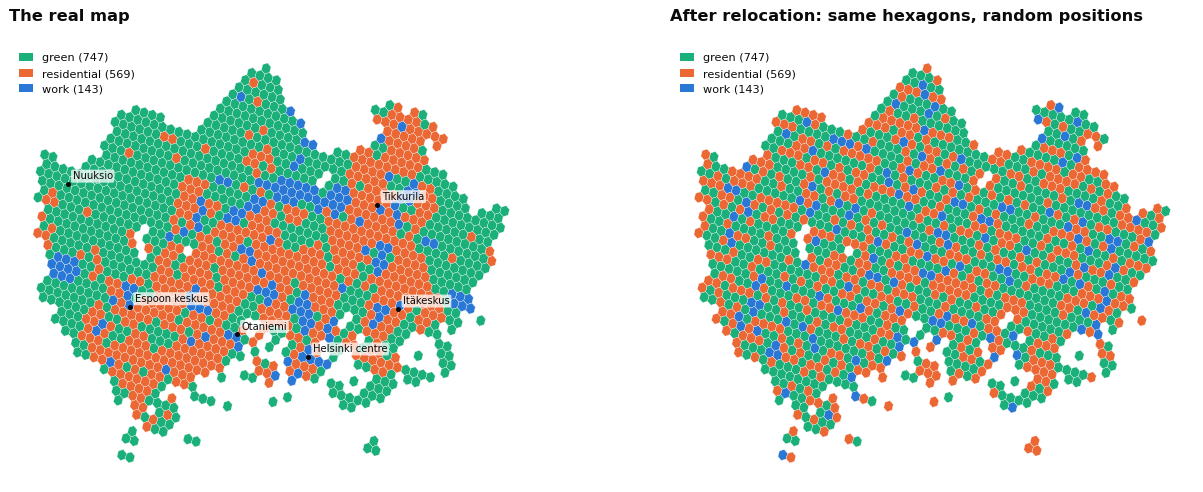

In [47]:
rng = np.random.default_rng(SEED)
new_position = rng.permutation(len(y))        # hexagon i moves to where hexagon new_position[i] used to be
occupant = np.argsort(new_position)           # occupant[p] = the hexagon that now sits at position p

moved = {
    "POIs only": X,                                                               # nothing in here knows about location
    "POIs + neighbours' profile": np.hstack([X, (W @ X[occupant])[new_position]]),  # profile of the NEW neighbours
    "POIs + coordinates": np.hstack([X, xy[new_position]]),                       # the NEW coordinates
}
after = {name: models[name].predict(F[test]) for name, F in moved.items()}                               # question 1
retrained = {name: new_forest().fit(F[train], y[train]).predict(F[test]) for name, F in moved.items()}   # question 2

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
h.map_classes(hexes, y, ax=axes[0], title="The real map")
h.map_classes(hexes, y[occupant], ax=axes[1], places=False, title="After relocation: same hexagons, random positions")
plt.tight_layout()
h.save(fig, "3_relocation_maps.png", SAVE)
plt.show()

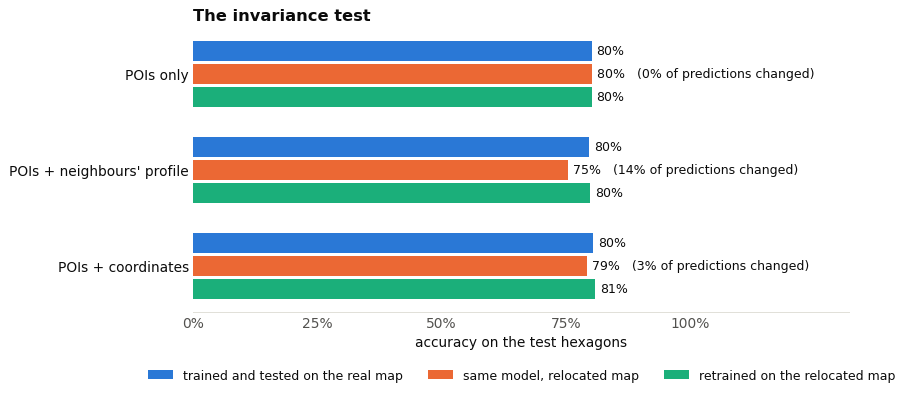

In [48]:
names = list(versions)
acc = lambda pred: (pred == y[test]).mean()
acc_real = [acc(before[n]) for n in names]
acc_same = [acc(after[n]) for n in names]
acc_new = [acc(retrained[n]) for n in names]
changed = [(before[n] != after[n]).mean() for n in names]

fig, ax = plt.subplots(figsize=(10, 4.6))
pos = np.arange(len(names))[::-1] * 1.25
ax.barh(pos + 0.3, acc_real, height=0.27, color="#2a78d6", label="trained and tested on the real map")
ax.barh(pos, acc_same, height=0.27, color="#eb6834", label="same model, relocated map")
ax.barh(pos - 0.3, acc_new, height=0.27, color="#1baf7a", label="retrained on the relocated map")
for p, a, b, c, ch in zip(pos, acc_real, acc_same, acc_new, changed):
    ax.text(a + 0.01, p + 0.3, f"{a:.0%}", va="center", fontsize=10)
    ax.text(b + 0.01, p, f"{b:.0%}   ({ch:.0%} of predictions changed)", va="center", fontsize=10)
    ax.text(c + 0.01, p - 0.3, f"{c:.0%}", va="center", fontsize=10)
ax.set_yticks(pos, names)
ax.set_xlim(0, 1.32)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0], ["0%", "25%", "50%", "75%", "100%"])
ax.set_xlabel("accuracy on the test hexagons")
ax.set_title("The invariance test")
ax.tick_params(length=0)
ax.spines["left"].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=10)
plt.tight_layout()
h.save(fig, "3_invariance_test.png", SAVE)
plt.show()

> **What did we just see?** Compare blue and orange for question 1. The model that only sees POIs gives exactly the same answers after relocation. That is true by construction: location was never among its inputs, so it cannot notice. The other two change some of their answers, so by Goodchild's test they are spatially explicit, although all three were trained on "spatial data".
>
> Compare blue and green for question 2. If a model retrained on the scrambled map is as accurate as the model trained on the real map, the real arrangement of the hexagons was worth nothing to it. The orange bar must not be read that way: it shows a model that meets inputs unlike those it was trained on, and such a model loses accuracy whether or not location was useful.
>
> Being spatially explicit and being *better* are therefore two different things. Whether the neighbours add information depends on the task and on the size of the units, which the section *Going deeper* looks at.

## Going deeper

**Smaller units.** The same region is also available at H3 resolution 9, where a hexagon is seven times smaller (about 0.08 km²) and holds far fewer POIs. We ask question 2 at both sizes: what is the spatial arrangement worth to the model that sees the neighbours' profile? This cell is *slow* (about half a minute).

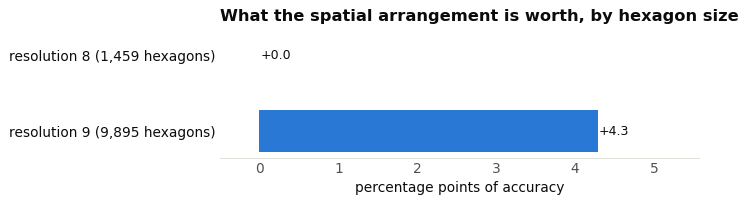

,hexagons,median POIs per hexagon,POIs only,"with neighbours, real map","with neighbours, relocated map",worth of the arrangement (points)
resolution 8,1459.0,15.0,0.797,0.797,0.797,0.000
resolution 9,9895.0,1.0,0.749,0.785,0.743,4.289


In [49]:
def worth_of_the_arrangement(res, relocations=3):
    g = h.load_hexagons(res)
    Xg, yg, Wg = np.log1p(g[FEATURES].to_numpy(float)), g["landuse"].to_numpy(), h.neighbour_matrix(g)
    tr, te = train_test_split(np.arange(len(yg)), test_size=0.3, stratify=yg, random_state=SEED)
    fit_score = lambda F: (new_forest(150).fit(F[tr], yg[tr]).predict(F[te]) == yg[te]).mean()
    real = fit_score(np.hstack([Xg, Wg @ Xg]))
    scrambled = []
    for s in range(relocations):
        pos = np.random.default_rng(s).permutation(len(yg))
        scrambled.append(fit_score(np.hstack([Xg, (Wg @ Xg[np.argsort(pos)])[pos]])))
    return {"hexagons": len(g), "median POIs per hexagon": g["poi_total"].median(), "POIs only": fit_score(Xg),
            "with neighbours, real map": real, "with neighbours, relocated map": np.mean(scrambled),
            "worth of the arrangement (points)": (real - np.mean(scrambled)) * 100}


try:
    by_size = pd.DataFrame({f"resolution {r}": worth_of_the_arrangement(r) for r in (8, 9)}).T
    worth = by_size["worth of the arrangement (points)"]
    fig, ax = plt.subplots(figsize=(8, 2.4))
    h.bars(ax, [f"{name} ({int(n):,} hexagons)" for name, n in by_size["hexagons"].items()], worth.tolist(),
           title="What the spatial arrangement is worth, by hexagon size", xlabel="percentage points of accuracy",
           xlim=(min(0, worth.min()) - 0.5, max(1, worth.max()) * 1.3), fmt="{:+.1f}")
    plt.tight_layout()
    h.save(fig, "3_hexagon_size.png", SAVE)
    plt.show()
    display(by_size.round(3))
except FileNotFoundError as err:
    print(err)

> **What did we just see?** At resolution 8 a hexagon holds enough POIs to describe itself, and the arrangement of its neighbours is worth nothing to the model. At resolution 9 half of the hexagons hold one POI or none, and there the neighbours are worth several points. How much spatial dependence is worth depends on how much a unit says about itself.
>
> This is a scale effect of the kind you met in week 1 as the modifiable areal unit problem. Be careful with the comparison, though: with the hexagon size we changed the features, the labels and the class proportions together, since every label was derived again for the smaller hexagons.

## Your turn

- Add a second ring: `W @ X_around` is the average over the neighbours' neighbours. Does a wider view help?
- Set `RES = 9` in the setup cell and run the whole notebook again (it takes much longer). Which pages change their story, and which do not?
- The neighbours' *labels* would be a very strong feature. Why would it be cheating to use `W @ (y == "green")` as a feature here, and when would it be legitimate?
- Apply Goodchild's other three tests (representation, formulation, outcome) to the three models above. Which pass?
- Go back to methods from earlier weeks: Moran's I, kriging, k-means on attributes, shortest paths. Which of them would notice a relocation?

**Ask an AI assistant**

> Explain in plain language what a spatial lag feature is and how to compute it for a GeoDataFrame of polygons with libpysal, for a column called `food`. Then explain one situation in which adding it to a machine learning model would leak information from the test set.

Then check its answer against week 3: is the weights matrix row-standardised, and does the leakage example make sense for our hexagons?

# Challenges: can we believe the score?

<div class="roadmap"><div class="rm-sofar"><span>So far</span>Models that use location were scored on hexagons held out at random.</div><div class="rm-question"><b>Can we believe the score, and whom does the model serve?</b><span>A spatial split holds out whole areas. A model trained in two cities is tested in the third. The data carry the habits of those who mapped them.</span></div><div class="rm-steps"><div class="rm-step"><b>A random split</b><span>test hexagons beside training hexagons</span></div><div class="rm-step"><b>A spatial split</b><span>whole areas held out</span></div><div class="rm-step"><b>Three cities</b><span>train in two, test in the third</span></div><div class="rm-step"><b>Who mapped what</b><span>bias in our own data</span></div><div class="rm-step"><b>A research case</b><span>better data beat a cleverer model</span></div></div></div>

So far we judged models on hexagons picked **at random**. But a randomly picked test hexagon almost always has training hexagons right next to it, and we saw on the data page that neighbours are alike. The dependence that the earlier pages borrowed from also links every test hexagon to the training hexagons around it, so the test itself has to be examined.

The alternative is a **spatial split**: we cut the region into blocks and hold out entire blocks, so the model is tested on areas it was not trained on. In the literature this is called spatial, or blocked, cross-validation.

## The experiment

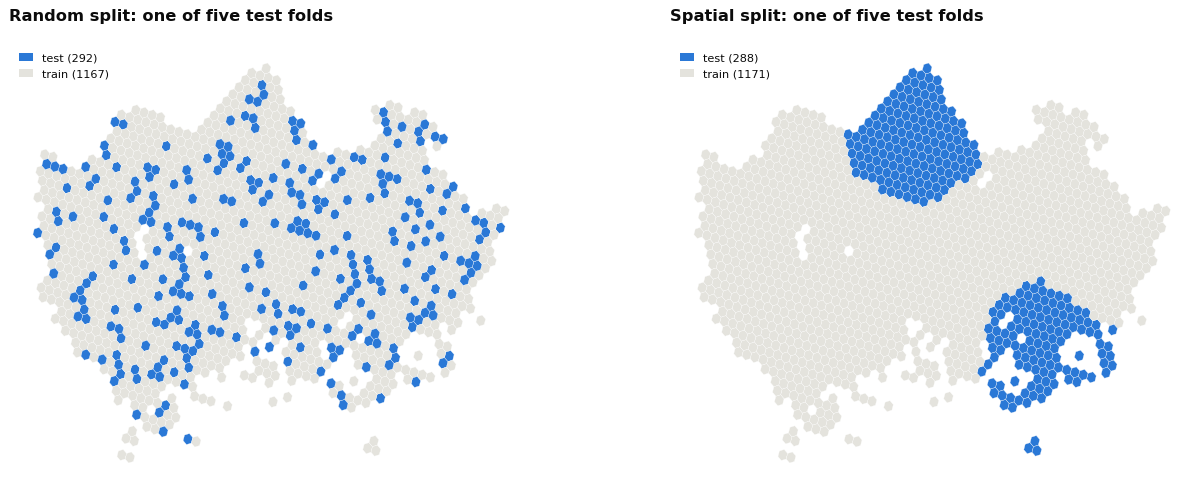

In [50]:
N_BLOCKS = 10
blocks = KMeans(n_clusters=N_BLOCKS, n_init=10, random_state=SEED).fit_predict(xy)     # compact spatial blocks

random_folds = StratifiedKFold(5, shuffle=True, random_state=SEED)
spatial_folds = GroupKFold(5)

random_test = np.zeros(len(y), dtype=int)
for k, (_, te) in enumerate(random_folds.split(X, y)):
    random_test[te] = k
spatial_test = np.zeros(len(y), dtype=int)
for k, (_, te) in enumerate(spatial_folds.split(X, y, groups=blocks)):
    spatial_test[te] = k

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
h.map_groups(hexes, random_test, ax=axes[0], highlight=0, title="Random split: one of five test folds")
h.map_groups(hexes, spatial_test, ax=axes[1], highlight=0, title="Spatial split: one of five test folds")
plt.tight_layout()
h.save(fig, "4_folds_maps.png", SAVE)
plt.show()

<img src="_static/figures/4_folds_cycle.gif" alt="Random and spatial folds, one after the other" class="wide">

*The five test folds of each split, one after the other: scattered hexagons on the left, whole areas on the right.*

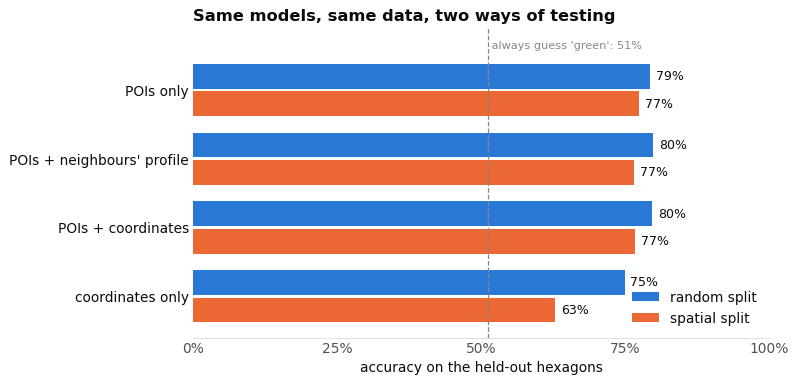

,random split,spatial split,overstated by (points)
POIs only,0.792,0.773,1.919
POIs + neighbours' profile,0.798,0.766,3.290
POIs + coordinates,0.796,0.766,3.016
coordinates only,0.748,0.629,11.995


In [51]:
def cv_predict(F, folds, groups=None, trees=200):
    return cross_val_predict(new_forest(trees), F, y, cv=folds, groups=groups)


feature_sets = {
    "POIs only": X,
    "POIs + neighbours' profile": np.hstack([X, X_around]),
    "POIs + coordinates": np.hstack([X, xy]),
    "coordinates only": xy,
}
pred_random = {name: cv_predict(F, random_folds) for name, F in feature_sets.items()}
pred_spatial = {name: cv_predict(F, spatial_folds, blocks) for name, F in feature_sets.items()}
cv = pd.DataFrame({"random split": {n: (p == y).mean() for n, p in pred_random.items()},
                   "spatial split": {n: (p == y).mean() for n, p in pred_spatial.items()}})
cv["overstated by (points)"] = (cv["random split"] - cv["spatial split"]) * 100
baseline = (y == "green").mean()

fig, ax = plt.subplots(figsize=(9, 4.4))
pos = np.arange(len(cv))[::-1]
ax.barh(pos + 0.2, cv["random split"], height=0.36, color="#2a78d6", label="random split")
ax.barh(pos - 0.2, cv["spatial split"], height=0.36, color="#eb6834", label="spatial split")
for p, (r, s) in zip(pos, zip(cv["random split"], cv["spatial split"])):
    ax.text(r + 0.01, p + 0.2, f"{r:.0%}", va="center", fontsize=10)
    ax.text(s + 0.01, p - 0.2, f"{s:.0%}", va="center", fontsize=10)
ax.axvline(baseline, color=h.MUTED, linestyle="--", linewidth=1)
ax.text(baseline, len(cv) - 0.42, f" always guess 'green': {baseline:.0%}", color=h.MUTED, fontsize=9, va="bottom")
ax.set_yticks(pos, cv.index)
ax.set_ylim(-0.6, len(cv) - 0.1)
ax.set_xlim(0, 1.0)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0], ["0%", "25%", "50%", "75%", "100%"])
ax.set_xlabel("accuracy on the held-out hexagons")
ax.set_title("Same models, same data, two ways of testing")
ax.tick_params(length=0)
ax.spines["left"].set_visible(False)
ax.legend(loc="lower right")
plt.tight_layout()
h.save(fig, "4_random_vs_spatial_cv.png", SAVE)
plt.show()
cv.round(3)

> **What did we just see?** Read the last column from top to bottom. The model that sees only POIs is overstated a little by the random split, the models that also see the neighbours or the coordinates somewhat more, and the model that knows *nothing but the coordinates* by far the most. That last model is a deliberate extreme: it has simply memorised the map ("around here it is mostly forest"), and asked about an area it was not trained on, it falls back towards guessing.
>
> The more a model can use location, the more a random split overstates it. The two splits answer different questions. A random split asks how well the model fills gaps in an area that was already sampled. A spatial split asks how well it works somewhere new.

**What accuracy hides.** One number for three classes of very different size can hide a great deal.

In [52]:
p = pred_spatial["POIs only"]
recall = {c: (p[y == c] == c).mean() for c in CLASSES}
print("POIs only, spatial split")
print(f"  accuracy {(p == y).mean():.0%}   balanced accuracy {balanced_accuracy_score(y, p):.0%}")
for c in CLASSES:
    print(f"  of the {int((y == c).sum()):4d} {c:11s} hexagons the model finds {recall[c]:.0%}")

POIs only, spatial split
  accuracy 77%   balanced accuracy 64%
  of the  747 green       hexagons the model finds 86%
  of the  569 residential hexagons the model finds 78%
  of the  143 work        hexagons the model finds 28%


> **What did we just see?** The model is good at the two large classes and poor at the small one. Accuracy rewards getting the large classes right. *Balanced accuracy* is the average of the three shares above, and it treats the classes equally. Which of the two you report should depend on which class matters for the decision the map supports.

## Going deeper

**One block layout is also an anecdote.** We repeat both splits with five different random seeds and five different block layouts, for three of the feature sets. This cell is *slow* (about a minute).

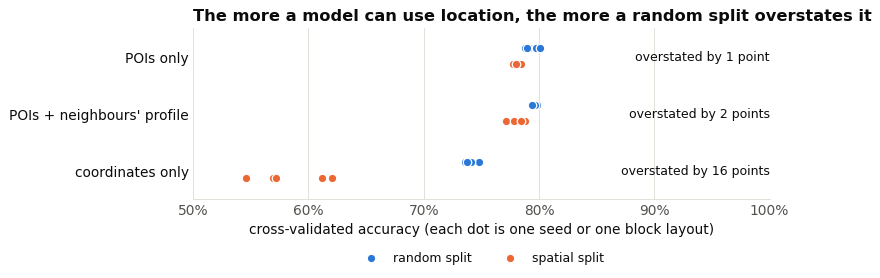

mean                        std  \
split                      random split spatial split random split   
features                                                             
POIs only                          79.3          78.0          0.5   
POIs + neighbours' profile         79.7          78.1          0.2   
coordinates only                   74.0          58.4          0.5   

                                          
split                      spatial split  
features                                  
POIs only                            0.3  
POIs + neighbours' profile           0.7  
coordinates only                     3.1

In [53]:
rows = []
for name in ["POIs only", "POIs + neighbours' profile", "coordinates only"]:
    for s in range(5):
        r = (cv_predict(feature_sets[name], StratifiedKFold(5, shuffle=True, random_state=s), trees=100) == y).mean()
        b = KMeans(n_clusters=N_BLOCKS, n_init=3, random_state=s).fit_predict(xy)
        sp = (cv_predict(feature_sets[name], GroupKFold(5), b, trees=100) == y).mean()
        rows += [{"features": name, "split": "random split", "accuracy": r}, {"features": name, "split": "spatial split", "accuracy": sp}]
spread = pd.DataFrame(rows)
summary = spread.groupby(["features", "split"], sort=False)["accuracy"].agg(["mean", "std"]).unstack()
gap = (summary[("mean", "random split")] - summary[("mean", "spatial split")]) * 100

fig, ax = plt.subplots(figsize=(9, 3.4))
order = ["POIs only", "POIs + neighbours' profile", "coordinates only"]
for i, name in enumerate(order[::-1]):
    for split, color, dy in (("random split", "#2a78d6", 0.14), ("spatial split", "#eb6834", -0.14)):
        v = spread[(spread["features"] == name) & (spread["split"] == split)]["accuracy"]
        ax.scatter(v, np.full(len(v), i + dy), s=46, color=color, edgecolor="white", linewidth=1, zorder=3, label=split if i == 0 else None)
    points = round(gap[name])
    ax.text(1.0, i, f"overstated by {points} point{'s' if points != 1 else ''}", va="center", ha="right", fontsize=10)
ax.set_yticks(range(3), order[::-1])
ax.set_xlim(0.5, 1.0)
ax.set_ylim(-0.5, 2.5)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("cross-validated accuracy (each dot is one seed or one block layout)")
ax.set_title("The more a model can use location, the more a random split overstates it")
ax.xaxis.grid(True, color=h.GRID)
ax.tick_params(length=0)
ax.spines["left"].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2, fontsize=10)
plt.tight_layout()
h.save(fig, "4_gap_spread.png", SAVE)
plt.show()
(summary * 100).round(1)

**How big should the blocks be?** With many tiny blocks, every test hexagon again has training neighbours and we are back at the random split. With a few huge blocks the test is hard, and we have few of them. Note also that our blocks touch: a test hexagon on the edge of a block still has training neighbours on the other side.

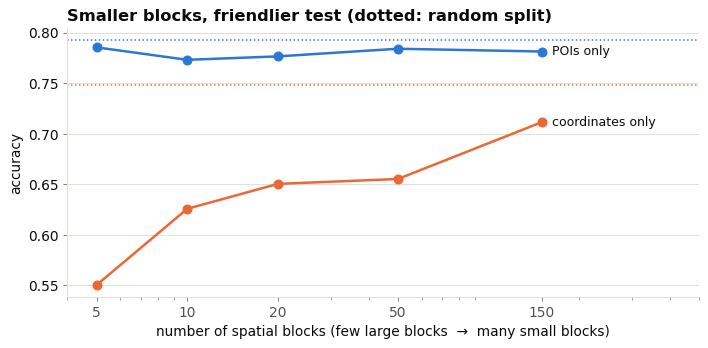

In [54]:
sweep = []
for n_blocks in [5, 10, 20, 50, 150]:
    b = KMeans(n_clusters=n_blocks, n_init=5, random_state=SEED).fit_predict(xy)
    for name in ["POIs only", "coordinates only"]:
        sweep.append({"blocks": n_blocks, "features": name,
                      "accuracy": (cv_predict(feature_sets[name], GroupKFold(5), b, trees=100) == y).mean()})
sweep = pd.DataFrame(sweep)

fig, ax = plt.subplots(figsize=(8, 4))
for name, color in [("POIs only", "#2a78d6"), ("coordinates only", "#eb6834")]:
    part = sweep[sweep["features"] == name]
    ax.plot(part["blocks"], part["accuracy"], marker="o", markersize=7, linewidth=2, color=color)
    ax.annotate(name, (part["blocks"].iloc[-1], part["accuracy"].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=10)
    ax.axhline(cv.loc[name, "random split"], color=color, linestyle=":", linewidth=1.2)
ax.set_xscale("log")
ax.set_xticks(sweep["blocks"].unique(), sweep["blocks"].unique())
ax.set_xlim(4, 500)
ax.set_xlabel("number of spatial blocks (few large blocks  →  many small blocks)")
ax.set_ylabel("accuracy")
ax.set_title("Smaller blocks, friendlier test (dotted: random split)")
ax.yaxis.grid(True, color=h.GRID)
plt.tight_layout()
h.save(fig, "4_block_size.png", SAVE)
plt.show()

**Re-reading the invariance experiment with a spatial split.** On the page before we judged the neighbours' profile on hexagons held out at random, which we now know favours a model that uses location. What do the neighbours add at resolution 9 when the test is a spatial split? This cell is *slow* (about a minute and a half).

In [55]:
try:
    g9 = h.load_hexagons(9)
    X9, y9, W9, xy9 = np.log1p(g9[FEATURES].to_numpy(float)), g9["landuse"].to_numpy(), h.neighbour_matrix(g9), g9[["x", "y"]].to_numpy()
    F9 = np.hstack([X9, W9 @ X9])
    b9 = KMeans(n_clusters=N_BLOCKS, n_init=3, random_state=SEED).fit_predict(xy9)
    score9 = lambda F, folds, groups=None: (cross_val_predict(new_forest(100), F, y9, cv=folds, groups=groups) == y9).mean()
    gain_random = score9(F9, random_folds) - score9(X9, random_folds)
    gain_spatial = score9(F9, spatial_folds, b9) - score9(X9, spatial_folds, b9)
    print(f"What the neighbours' profile adds at resolution 9: {gain_random * 100:+.1f} points with a random split, {gain_spatial * 100:+.1f} with a spatial split.")
except FileNotFoundError as err:
    print(err)

What the neighbours' profile adds at resolution 9: +2.9 points with a random split, +2.1 with a spatial split.


> **What did we just see?** Part of the gain that we credited to the neighbours was the random split speaking. The gain does not vanish, so the neighbours do carry information about small hexagons, but an honest figure needs the test that matches the use.

**A new city.** The widest test this dataset allows: train on two municipalities and predict the third. For comparison we also train a model inside each city alone. (Kauniainen has two hexagons and is counted with Espoo.)

In [56]:
city = hexes["municipality"].replace({"Kauniainen": "Espoo"}).to_numpy()
rows = []
for target in ["Helsinki", "Espoo", "Vantaa"]:
    te = city == target
    elsewhere = new_forest().fit(X[~te], y[~te]).predict(X[te])
    at_home = cross_val_predict(new_forest(), X[te], y[te], cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
    rows.append({"tested on": target, "hexagons": int(te.sum()),
                 "largest class there": f"{pd.Series(y[te]).value_counts(normalize=True).iloc[0]:.0%}",
                 "trained in the other two": (elsewhere == y[te]).mean(),
                 "trained in this city only": (at_home == y[te]).mean(),
                 "balanced accuracy, trained elsewhere": balanced_accuracy_score(y[te], elsewhere)})
cities = pd.DataFrame(rows)
cities.round(3)

,tested on,hexagons,largest class there,trained in the other two,trained in this city only,"balanced accuracy, trained elsewhere"
0,Helsinki,463,46%,0.732,0.728,0.595
1,Espoo,617,58%,0.825,0.841,0.623
2,Vantaa,379,52%,0.749,0.749,0.604


> **What did we just see?** The three cities get three different accuracies, and it is tempting to read that as a model that travels badly. Compare the two accuracy columns before you do. A model trained only inside a city scores about the same as a model that never saw it, so the differences between the cities come from their land-use mix (Espoo is mostly green, which is easy) and not from the journey. Balanced accuracy, which ignores the mix, is nearly the same in all three.
>
> The model transfers between these cities because they resemble each other: neighbouring Finnish municipalities, mapped by the same community. A test inside one region therefore says nothing yet about a place that does not resemble it. Regions differ, in what is built and in how it is mapped. Week 3 called this *spatial heterogeneity*, and it is where the geographic bias of the lecture begins.

**Is the map equally detailed everywhere?** Our features are whatever volunteers have mapped. Compare what a typical residential hexagon contains in the three cities.

In [57]:
detail = (hexes.assign(city=city)[hexes["landuse"] == "residential"]
          .groupby("city")[["poi_total", "street_furniture", "bike", "car", "shop_daily"]].median().astype(int))
share = hexes[["street_furniture", "car", "bike"]].sum().sum() / hexes[FEATURES].sum().sum()
print(f"Street furniture, car facilities and bicycle facilities make up {share:.0%} of all points of interest.")
print("Median number of POIs in a residential hexagon:")
detail

Street furniture, car facilities and bicycle facilities make up 59% of all points of interest.
Median number of POIs in a residential hexagon:


,poi_total,street_furniture,bike,car,shop_daily
city,,,,,
Espoo,40,6,1,14,0
Helsinki,86,26,7,24,1
Vantaa,37,7,1,10,0


> **What did we just see?** A residential hexagon in Helsinki holds several times more street furniture and bicycle facilities than one in Espoo or Vantaa. Helsinki is denser, and it may also simply be mapped in more detail; these data cannot tell the two apart. A model trained on such features learns partly where mappers have been busy. That is representational bias inside our own small dataset, before any model crosses a border.

## A case from research: better data beat a cleverer model

The same lesson appeared in the author's research on transport emissions. The task was to predict the daily CO₂ of the car trips that start in a hexagon (172 hexagons of about 5 km² in the Helsinki region), from the residents and jobs of the hexagon, with and without an embedding of its travel times. R² on held-out hexagons:

| Features | Random split | Spatial split |
|---|---|---|
| residents and jobs | 0.67 | 0.63 |
| residents and jobs + travel-time embedding | 0.71 | 0.64 |

Under a random split the embedding seems to add 4 points. Under a spatial split it adds 1, which is within the noise of the test. The gain appears only when the test hexagons lie next to training hexagons.

The case holds a second lesson. Residents and jobs are published by postal area, not by hexagon. In a first version they were spread over the hexagons of each postal area by ground area, which puts people into forests and lakes. With those figures, residents and jobs explained only 0.38, and the embedding seemed to add 15 points under the random split. Placing residents by the floor area of residential buildings and jobs by the floor area of other buildings raised that score to 0.63, and most of the apparent gain of the embedding disappeared: it had been repairing badly placed residents and jobs. A better measurement of the obvious variable was worth more than a cleverer model.

*Source: emission accounting with the GEMMAT model (Dey, Marín-Flores and Tenkanen, 2026); residents and jobs from the postal-code statistics of Statistics Finland (Paavo 2024) and the building grid of HSY (2024).*

## Your turn

- Map the errors: `h.map_values(hexes, (pred_spatial["POIs only"] != y).astype(int), cmap="Reds")`. Are the mistakes scattered or clustered? What would Moran's I say?
- Is 69% of neighbours sharing a label more than chance? Run a join-count test from week 3 on the labels.
- Our blocks touch. Remove from each training fold the hexagons within one or two rings of a test hexagon (a *buffer*) and see whether the spatial-split accuracy drops further.
- Use square blocks instead of k-means blocks: `blocks = (xy[:, 0] // 5000).astype(int) * 1000 + (xy[:, 1] // 5000).astype(int)`.
- Go back to the page on semi-supervised learning. Self-training was judged on hexagons scattered among the labelled ones. For which use of the map is that a fair test, and for which is it not?
- For a project of your own: which split matches the way the model will actually be used?

**Ask an AI assistant**

> I am training a scikit-learn classifier on spatial data with strong spatial autocorrelation. Explain why a random train/test split can overestimate accuracy, and show how to do spatially blocked cross-validation with `GroupKFold`. Then list two situations in which a random split is still the right choice.

Then check its answer: does it create the blocks from the coordinates, and does it keep whole blocks together?

In [58]:
# Only for the teacher: export the animation frames used on the fallback slides (set GEOAI_SAVE_FIGS=1).
if SAVE:
    frames = []
    for r, y_r in enumerate(history):
        fig, ax = plt.subplots(figsize=(9.6, 6.4))
        adopted = pd.notna(y_r) & hidden
        right = f"{(y_r[adopted] == y[adopted]).mean():.0%} of adopted labels right" if adopted.any() else "only the 30 labels we were given"
        h.map_classes(hexes, y_r, ax=ax, outline=labelled,
                      title=f"Self-training, round {r}: {pd.notna(y_r).sum()} of {len(y)} hexagons labelled · {right}")
        frames.append(h.save(fig, f"steps/1_selftraining_round_{r:02d}.png"))
        plt.close(fig)
    h.make_gif(frames, "1_selftraining_spread.gif", seconds=1.0)

    frames = []
    for k in range(5):
        fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
        h.map_groups(hexes, random_test, ax=axes[0], highlight=k, title=f"Random split: test fold {k + 1} of 5")
        h.map_groups(hexes, spatial_test, ax=axes[1], highlight=k, title=f"Spatial split: test fold {k + 1} of 5")
        plt.tight_layout()
        frames.append(h.save(fig, f"steps/4_folds_{k + 1}.png"))
        plt.close(fig)
    h.make_gif(frames, "4_folds_cycle.gif", seconds=1.5, hold_last=1.5)
    print("figures written to the folder", h.FIGURES.name)

figures written to the folder figures


# Doing this with your own data

## Where to find data like this

| Source | What you get | Notes |
|---|---|---|
| [Overpass Turbo](https://overpass-turbo.eu/) | OpenStreetMap features for a small area, straight from the browser, exportable as GeoJSON | Good for one neighbourhood or one tag. The public server is meant for small, hand-run queries |
| [Geofabrik extract for Finland](https://download.geofabrik.de/europe/finland.html) | All of OpenStreetMap for Finland as one file (`.osm.pbf`, shapefile or GeoPackage), updated regularly | The right choice for a whole city or region. Licence ODbL 1.0 |
| [`osmnx`](https://osmnx.readthedocs.io/) | OpenStreetMap from Python: `ox.features_from_place("Otaniemi, Espoo", {"amenity": True})` | What `build_dataset.py` uses |
| [HSY open data](https://www.hsy.fi/en/environmental-information/open-data/) | Land cover, buildings, population and environmental data for the capital region | Licence CC BY 4.0 |
| Helsinki Region Infoshare (hri.fi) | Open data from the cities of the region: services, traffic, statistics by district | |
| CSC Paituli (paituli.csc.fi) | Finnish spatial datasets for universities, including statistical grids | Some datasets are for research and teaching use only; check the licence of each |
| [AlphaEarth Satellite Embedding](https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_SATELLITE_EMBEDDING_V1_ANNUAL) | A ready-made 64-number embedding for every 10 m pixel of the land surface, yearly from 2017 to 2024 | Needs a Google Earth Engine account. Licence CC BY 4.0 |
| [H3](https://h3geo.org/) | The hexagon grid itself. Resolution 8 is about 0.74 km² per cell on average over the globe and about 0.57 km² at the latitude of Helsinki; resolution 9 is about 0.105 km² on average and 0.08 km² here | Python package `h3` |

OpenStreetMap data must be credited ("© OpenStreetMap contributors") and you must say that it is available under the Open Database License.

## A recipe for your own hexagon table

1. **Pick a question and a target.** Something you can map: noise complaints, building age, tree cover, rents, bike counts.
2. **Pick the unit.** A hexagon size that matches the phenomenon. Remember the page on spatially explicit models: the answer can change with the unit.
3. **Decide how the labelled places are chosen**, and say so. The page on semi-supervised learning showed how much depends on it.
4. **Build features per unit** from data that is not the target in disguise.
5. **Look at the map** of the target and of two or three features before any modelling.
6. **Decide how you will test** before you train (the page on challenges), and report more than one number.
7. **Start with the simplest model** and add geography on purpose (the page on spatially explicit models), so you can tell what it bought you.

## Working with an AI assistant

An assistant is good at producing a first version of code like `build_dataset.py`. It is also confidently wrong in ways that are specific to spatial data. A workable routine:

**1. Give it the facts it cannot guess.** Library versions, the coordinate reference system, column names, the area, the size of the data.

> I use Python with geopandas 1.x, osmnx 2.x and h3 version 4. Write a script that downloads all OpenStreetMap features tagged `amenity` or `shop` for Tampere, Finland, lays an H3 resolution 8 grid over the city, and counts features per hexagon and per tag value. Return a GeoDataFrame in EPSG:3067 with one row per hexagon. Keep it under 60 lines and comment each step.

**2. Ask for one step at a time, each with a check.**

> Before going on, add a line that prints the number of hexagons and plots them over the city boundary so I can see that the grid covers the city.

**3. Check the things assistants most often get wrong with spatial data.**

| Check | Why |
|---|---|
| Does the code run with *your* library versions? | Function names change. In `h3`, version 3 has `geo_to_h3` and `k_ring`, version 4 has `latlng_to_cell` and `grid_disk`. Assistants mix them freely. The build script for this notebook had to handle both |
| Is every distance and area computed in a metric CRS? | Buffers and areas in degrees are meaningless. Finland: EPSG:3067 |
| Longitude and latitude in the right order? | Some functions want (lat, lng), others (x, y) = (lng, lat) |
| Does the map look right? | A grid in the sea or a city in the wrong country is obvious on a map and invisible in a table |
| How were the labelled examples chosen, and how was the model tested? | Assistants reach for a balanced sample and for `train_test_split` by default. You now know what each of them does to a result |
| Is a feature the target in disguise? | In this notebook parks were kept out of the POI features, because parks help define the `green` label |
| Licence and attribution? | The assistant will not add them for you |

**4. Ask it to explain, and then verify the explanation yourself.** An assistant that can produce the code can also produce a plausible wrong reason for why it works. A plausible explanation is not evidence, so test the claim: change the sample, the split or the seed, and see whether the result survives.

Check the course rules on AI use before using an assistant for graded work.

## What to remember

1. **Learning:** a program learns if its performance at a task improves with experience. On our hexagons the accuracy rose with the number of hexagons whose land use the program was given.
2. **Unsupervised:** clustering finds groups of similar rows without any answer. Someone has to name the groups afterwards.
3. **Supervised:** a rule with parameters is fitted to rows with known answers and scored on rows it has not seen. Its flexibility is a setting chosen on a validation pile.
4. **Spatial dependence:** places resemble their neighbours. The methods of part 2 borrow from that resemblance, and a test has to guard against it.
5. **Semi-supervised:** unlabelled data helped where the labelled sample misrepresented the map, and little where it did not. How the labelled places are chosen matters as much as the method.
6. **Self-supervised:** a model can learn a description of places, an embedding, from a task that needs no labels. Ours supported search and did not improve prediction.
7. **Reinforcement:** an agent learns from the rewards that follow its own actions. It needs no table of examples.
8. **Spatially explicit:** a model is spatial when relocating the data changes its results. What the spatial arrangement is worth depends on how much a unit says about itself.
9. **Testing:** a random split overstates a model in proportion to its use of location. Report more than one number.
10. **Spatial heterogeneity:** regions differ, in what is built and in how it is mapped, so a test in one region does not license use in another.